In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

file_path = "../data/loan_data.csv"

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (307511, 122)


In [3]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB


In [5]:
print(df.columns.tolist())

['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELE

In [6]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [7]:
target_counts = df["TARGET"].value_counts(dropna=False)

print("TARGET value counts:")
print(target_counts)

TARGET value counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64


In [8]:
target_percentages = df["TARGET"].value_counts(normalize=True, dropna=False) * 100

print("TARGET percentages:")
print(target_percentages)

TARGET percentages:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [9]:
print("Unique TARGET values:")
print(df["TARGET"].unique())

Unique TARGET values:
[1 0]


In [10]:
null_counts = df.isnull().sum()

print("Total missing values in the dataset:", null_counts.sum())

Total missing values in the dataset: 9152465


In [11]:
null_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

null_summary = null_summary.sort_values(
    by="Missing Count",
    ascending=False
)

null_summary

,Missing Count,Missing Percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
...,...,...
FLAG_DOCUMENT_16,0,0.000000
FLAG_DOCUMENT_15,0,0.000000
FLAG_DOCUMENT_14,0,0.000000
FLAG_DOCUMENT_20,0,0.000000


In [12]:
missing_data = null_summary[null_summary["Missing Count"] > 0]

print("Number of columns containing missing values:", len(missing_data))

missing_data

Number of columns containing missing values: 67


,Missing Count,Missing Percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
...,...,...
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650


In [13]:
print("Missing values in TARGET:", df["TARGET"].isnull().sum())

Missing values in TARGET: 0


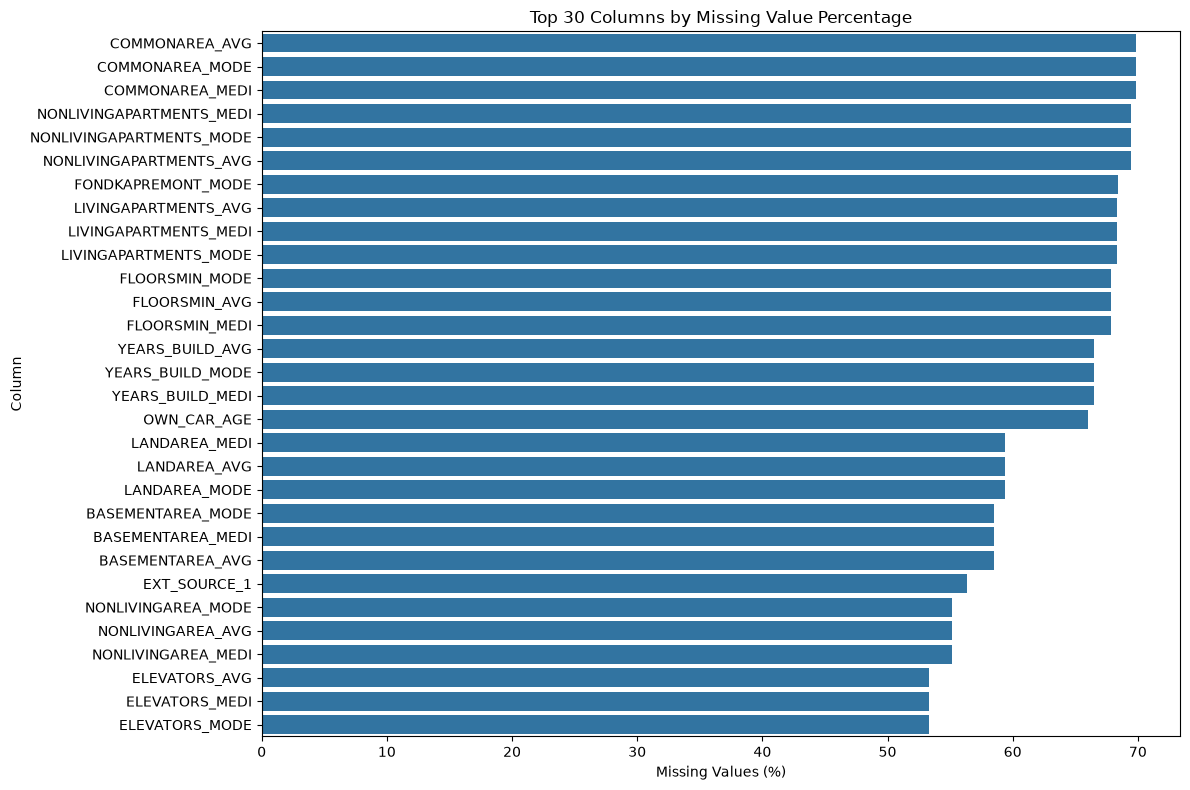

In [14]:
missing_plot_data = missing_data.head(30)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=missing_plot_data["Missing Percentage"],
    y=missing_plot_data.index
)

plt.title("Top 30 Columns by Missing Value Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [15]:
high_missing = missing_data[missing_data["Missing Percentage"] >= 50]

print(
    "Columns with 50% or more missing values:",
    len(high_missing)
)

high_missing

Columns with 50% or more missing values: 41


,Missing Count,Missing Percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [16]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [17]:
print(
    f"Duplicate percentage: "
    f"{(duplicate_count / len(df)) * 100:.2f}%"
)

Duplicate percentage: 0.00%


In [18]:
data_quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Total Missing Values",
        "Columns With Missing Values",
        "Columns With >=50% Missing Values",
        "Duplicate Rows"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        (df.isnull().sum() > 0).sum(),
        (df.isnull().sum() / len(df) * 100 >= 50).sum(),
        df.duplicated().sum()
    ]
})

data_quality_summary

,Metric,Value
0,Total Rows,307511
1,Total Columns,122
2,Total Missing Values,9152465
3,Columns With Missing Values,67
4,Columns With >=50% Missing Values,41
5,Duplicate Rows,0


In [19]:
null_counts = df.isnull().sum()

print("Total missing values in the dataset:", null_counts.sum())

Total missing values in the dataset: 9152465


In [20]:
null_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

null_summary = null_summary.sort_values(
    by="Missing Count",
    ascending=False
)

null_summary

,Missing Count,Missing Percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
...,...,...
FLAG_DOCUMENT_16,0,0.000000
FLAG_DOCUMENT_15,0,0.000000
FLAG_DOCUMENT_14,0,0.000000
FLAG_DOCUMENT_20,0,0.000000


In [21]:
missing_data = null_summary[null_summary["Missing Count"] > 0]

print(
    "Number of columns containing missing values:",
    len(missing_data)
)

missing_data

Number of columns containing missing values: 67


,Missing Count,Missing Percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
...,...,...
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650


In [22]:
print("Missing values in TARGET:", df["TARGET"].isnull().sum())

Missing values in TARGET: 0


In [23]:
# Identify columns with at least 50% missing values
high_missing = missing_data[
    missing_data["Missing Percentage"] >= 50
]

print(
    "Columns with 50% or more missing values:",
    len(high_missing)
)

high_missing

Columns with 50% or more missing values: 41


,Missing Count,Missing Percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [24]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    f"Duplicate percentage: "
    f"{(duplicate_count / len(df)) * 100:.2f}%"
)

Number of duplicate rows: 0
Duplicate percentage: 0.00%


In [25]:
# Overall data-quality summary
data_quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Total Missing Values",
        "Columns With Missing Values",
        "Columns With >=50% Missing Values",
        "Missing Values in TARGET",
        "Duplicate Rows"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        (df.isnull().sum() > 0).sum(),
        (df.isnull().sum() / len(df) * 100 >= 50).sum(),
        df["TARGET"].isnull().sum(),
        df.duplicated().sum()
    ]
})

data_quality_summary

,Metric,Value
0,Total Rows,307511
1,Total Columns,122
2,Total Missing Values,9152465
3,Columns With Missing Values,67
4,Columns With >=50% Missing Values,41
5,Missing Values in TARGET,0
6,Duplicate Rows,0


In [26]:
# TARGET class distribution
target_counts = df["TARGET"].value_counts()

print("TARGET Class Distribution:")
print(target_counts)

TARGET Class Distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64


In [27]:
# TARGET class percentages
target_percentages = (
    df["TARGET"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("TARGET Class Percentages:")
print(target_percentages)

TARGET Class Percentages:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [28]:
# Detailed TARGET summary
target_summary = pd.DataFrame({
    "Class": target_counts.index,
    "Count": target_counts.values,
    "Percentage": (
        target_counts.values / len(df)
    ) * 100
})

target_summary

,Class,Count,Percentage
0,0,282686,91.927118
1,1,24825,8.072882


In [29]:
# Calculate class imbalance ratio

class_0_count = (df["TARGET"] == 0).sum()
class_1_count = (df["TARGET"] == 1).sum()

imbalance_ratio = class_0_count / class_1_count

print(f"Class 0 samples: {class_0_count:,}")
print(f"Class 1 samples: {class_1_count:,}")
print(f"Imbalance ratio (0:1): {imbalance_ratio:.2f}:1")

Class 0 samples: 282,686
Class 1 samples: 24,825
Imbalance ratio (0:1): 11.39:1


In [30]:
# Separate majority and minority classes

df_class_0 = df[df["TARGET"] == 0]
df_class_1 = df[df["TARGET"] == 1]

print("Class 0:", len(df_class_0))
print("Class 1:", len(df_class_1))

Class 0: 282686
Class 1: 24825


In [31]:
# Randomly sample class 0 to match the number of class 1 observations

df_class_0_balanced = df_class_0.sample(
    n=len(df_class_1),
    random_state=42
)

print("Balanced Class 0:", len(df_class_0_balanced))
print("Class 1:", len(df_class_1))

Balanced Class 0: 24825
Class 1: 24825


In [32]:
# Combine the balanced majority class with the minority class

df_balanced = pd.concat(
    [df_class_0_balanced, df_class_1],
    axis=0
)

# Shuffle the resulting dataset
df_balanced = df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Balanced dataset shape:", df_balanced.shape)

Balanced dataset shape: (49650, 122)


In [33]:
balanced_counts = df_balanced["TARGET"].value_counts()

print("Balanced TARGET distribution:")
print(balanced_counts)

Balanced TARGET distribution:
TARGET
0    24825
1    24825
Name: count, dtype: int64


In [34]:
balanced_percentages = (
    df_balanced["TARGET"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("Balanced TARGET percentages:")
print(balanced_percentages)

Balanced TARGET percentages:
TARGET
0    50.0
1    50.0
Name: proportion, dtype: float64


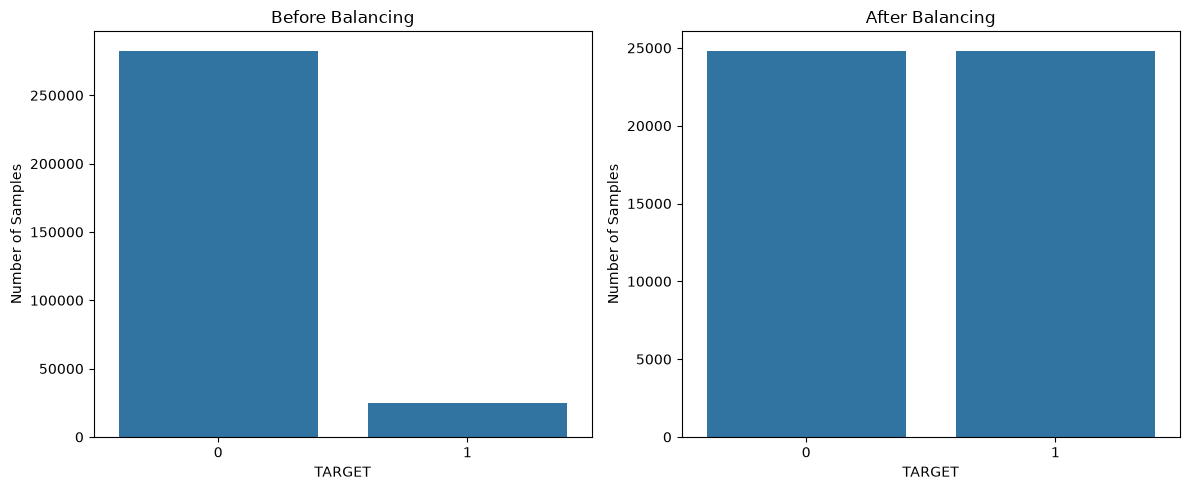

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=df,
    x="TARGET",
    ax=axes[0]
)

axes[0].set_title("Before Balancing")
axes[0].set_xlabel("TARGET")
axes[0].set_ylabel("Number of Samples")


sns.countplot(
    data=df_balanced,
    x="TARGET",
    ax=axes[1]
)

axes[1].set_title("After Balancing")
axes[1].set_xlabel("TARGET")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [36]:
print("\nOriginal dataset:")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]:,}")

print("\nBalanced dataset:")
print(f"Rows: {len(df_balanced):,}")
print(f"Columns: {df_balanced.shape[1]:,}")

print("\nOriginal TARGET distribution:")
print(df["TARGET"].value_counts())

print("\nBalanced TARGET distribution:")
print(df_balanced["TARGET"].value_counts())


Original dataset:
Rows: 307,511
Columns: 122

Balanced dataset:
Rows: 49,650
Columns: 122

Original TARGET distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Balanced TARGET distribution:
TARGET
0    24825
1    24825
Name: count, dtype: int64


In [37]:
# Identify categorical columns in the balanced dataset

categorical_columns = df_balanced.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
for col in categorical_columns:
    print("-", col)

Number of categorical columns: 16

Categorical columns:
- NAME_CONTRACT_TYPE
- CODE_GENDER
- FLAG_OWN_CAR
- FLAG_OWN_REALTY
- NAME_TYPE_SUITE
- NAME_INCOME_TYPE
- NAME_EDUCATION_TYPE
- NAME_FAMILY_STATUS
- NAME_HOUSING_TYPE
- OCCUPATION_TYPE
- WEEKDAY_APPR_PROCESS_START
- ORGANIZATION_TYPE
- FONDKAPREMONT_MODE
- HOUSETYPE_MODE
- WALLSMATERIAL_MODE
- EMERGENCYSTATE_MODE


In [38]:
# Show the number of unique values in each categorical column

categorical_summary = pd.DataFrame({
    "Column": categorical_columns,
    "Unique Values": [
        df_balanced[col].nunique(dropna=True)
        for col in categorical_columns
    ],
    "Missing Values": [
        df_balanced[col].isnull().sum()
        for col in categorical_columns
    ]
})

categorical_summary.sort_values(
    by="Unique Values",
    ascending=False
)

,Column,Unique Values,Missing Values
11,ORGANIZATION_TYPE,58,0
9,OCCUPATION_TYPE,18,14218
5,NAME_INCOME_TYPE,8,0
4,NAME_TYPE_SUITE,7,169
14,WALLSMATERIAL_MODE,7,26702
10,WEEKDAY_APPR_PROCESS_START,7,0
8,NAME_HOUSING_TYPE,6,0
7,NAME_FAMILY_STATUS,5,0
6,NAME_EDUCATION_TYPE,5,0
12,FONDKAPREMONT_MODE,4,35028


In [39]:
# Create a working copy for preprocessing

df_encoded = df_balanced.copy()

print("Working dataset shape:", df_encoded.shape)

Working dataset shape: (49650, 122)


In [40]:
# Separate target variable and remove the identifier

y = df_encoded["TARGET"].copy()

X = df_encoded.drop(
    columns=["TARGET", "SK_ID_CURR"]
)

print("Feature shape before encoding:", X.shape)
print("Target shape:", y.shape)

Feature shape before encoding: (49650, 120)
Target shape: (49650,)


In [41]:
# Identify categorical and numerical features

categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))
print("Number of numerical columns:", len(numerical_columns))

print("\nCategorical columns:")
for col in categorical_columns:
    print("-", col)

Number of categorical columns: 16
Number of numerical columns: 104

Categorical columns:
- NAME_CONTRACT_TYPE
- CODE_GENDER
- FLAG_OWN_CAR
- FLAG_OWN_REALTY
- NAME_TYPE_SUITE
- NAME_INCOME_TYPE
- NAME_EDUCATION_TYPE
- NAME_FAMILY_STATUS
- NAME_HOUSING_TYPE
- OCCUPATION_TYPE
- WEEKDAY_APPR_PROCESS_START
- ORGANIZATION_TYPE
- FONDKAPREMONT_MODE
- HOUSETYPE_MODE
- WALLSMATERIAL_MODE
- EMERGENCYSTATE_MODE


In [42]:
# Handle missing categorical values explicitly

X[categorical_columns] = X[categorical_columns].fillna("Missing")

print(
    "Remaining missing categorical values:",
    X[categorical_columns].isnull().sum().sum()
)

Remaining missing categorical values: 0


In [43]:
# One-hot encode categorical variables

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", X_encoded.shape)

Shape after encoding: (49650, 233)


In [44]:
# Verify that all remaining features are numerical

remaining_categorical = X_encoded.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(
    "Remaining categorical columns:",
    len(remaining_categorical)
)

if len(remaining_categorical) > 0:
    print(remaining_categorical)
else:
    print("All categorical variables have been successfully encoded.")

Remaining categorical columns: 0
All categorical variables have been successfully encoded.


In [45]:
# Inspect encoded dataset

print("Encoded feature matrix shape:", X_encoded.shape)

print("\nData types:")
print(X_encoded.dtypes.value_counts())

Encoded feature matrix shape: (49650, 233)

Data types:
int64      168
float64     65
Name: count, dtype: int64


In [46]:
X_encoded.head()

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,HOUSETYPE_MODE_terraced house,WALLSMATERIAL_MODE_Missing,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Wooden,EMERGENCYSTATE_MODE_No,EMERGENCYSTATE_MODE_Yes
0,0,90000.0,454500.0,25375.5,454500.0,0.026392,-22070,365243,-11899.0,-4078,...,0,0,0,0,0,1,0,0,1,0
1,0,72000.0,296280.0,16069.5,225000.0,0.035792,-18732,-589,-9693.0,-2268,...,0,1,0,0,0,0,0,0,0,0
2,0,99000.0,284400.0,18643.5,225000.0,0.007120,-11559,-1144,-3363.0,-2218,...,0,0,0,0,0,0,1,0,1,0
3,0,112500.0,308133.0,16843.5,234000.0,0.025164,-12821,-5913,-251.0,-639,...,0,1,0,0,0,0,0,0,0,0
4,0,450000.0,503266.5,57046.5,463500.0,0.006629,-12117,-172,-1213.0,-491,...,0,0,0,0,0,0,0,1,0,1


In [47]:
# Check missing values in the encoded feature matrix

total_missing_encoded = X_encoded.isnull().sum().sum()

print(
    "Total missing values remaining in encoded features:",
    total_missing_encoded
)

Total missing values remaining in encoded features: 1417765


In [48]:
# Final preprocessing summary

encoding_summary = pd.DataFrame({
    "Metric": [
        "Original Balanced Rows",
        "Original Feature Columns",
        "Categorical Columns",
        "Numerical Columns Before Encoding",
        "Encoded Feature Columns",
        "Remaining Categorical Columns",
        "Target Values"
    ],
    "Value": [
        len(X),
        X.shape[1],
        len(categorical_columns),
        len(numerical_columns),
        X_encoded.shape[1],
        len(remaining_categorical),
        y.nunique()
    ]
})

encoding_summary

,Metric,Value
0,Original Balanced Rows,49650
1,Original Feature Columns,120
2,Categorical Columns,16
3,Numerical Columns Before Encoding,104
4,Encoded Feature Columns,233
5,Remaining Categorical Columns,0
6,Target Values,2


In [49]:
X_encoded.isnull().sum().sum()

np.int64(1417765)

In [50]:
# Check remaining missing values in encoded features

total_missing = X_encoded.isnull().sum().sum()

print("Total missing values remaining:", total_missing)

Total missing values remaining: 1417765


In [51]:
# Show numerical columns with missing values

missing_numeric = pd.DataFrame({
    "Missing Count": X_encoded.isnull().sum(),
    "Missing Percentage": (
        X_encoded.isnull().sum() / len(X_encoded)
    ) * 100
})

missing_numeric = missing_numeric[
    missing_numeric["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print(
    "Number of columns with remaining missing values:",
    len(missing_numeric)
)

missing_numeric.head(20)

Number of columns with remaining missing values: 59


,Missing Count,Missing Percentage
COMMONAREA_AVG,35710,71.923464
COMMONAREA_MODE,35710,71.923464
COMMONAREA_MEDI,35710,71.923464
NONLIVINGAPARTMENTS_MODE,35477,71.454179
NONLIVINGAPARTMENTS_MEDI,35477,71.454179
NONLIVINGAPARTMENTS_AVG,35477,71.454179
LIVINGAPARTMENTS_AVG,35037,70.567976
LIVINGAPARTMENTS_MODE,35037,70.567976
LIVINGAPARTMENTS_MEDI,35037,70.567976
FLOORSMIN_MODE,34756,70.002014


In [52]:
print("Target missing values:", y.isnull().sum())
print("Target shape:", y.shape)

Target missing values: 0
Target shape: (49650,)


In [53]:
from sklearn.impute import SimpleImputer

# Create median imputer for numerical features
imputer = SimpleImputer(strategy="median")

X_imputed_array = imputer.fit_transform(X_encoded)

print("Shape after imputation:", X_imputed_array.shape)

Shape after imputation: (49650, 233)


In [54]:
# Convert imputed array back to DataFrame

X_imputed = pd.DataFrame(
    X_imputed_array,
    columns=X_encoded.columns,
    index=X_encoded.index
)

print("X_imputed shape:", X_imputed.shape)

X_imputed shape: (49650, 233)


In [55]:
# Verify missing values after imputation

remaining_missing = X_imputed.isnull().sum().sum()

print("Remaining missing values:", remaining_missing)

Remaining missing values: 0


In [56]:
print("Features:", X_imputed.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (49650, 233)
Target: (49650,)

Target distribution:
TARGET
0    24825
1    24825
Name: count, dtype: int64


In [57]:
from sklearn.model_selection import train_test_split

In [58]:
# Split BEFORE fitting the imputer

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

Training shape: (39720, 233)
Testing shape: (9930, 233)


In [59]:
from sklearn.impute import SimpleImputer

# Fit the imputer ONLY on the training data

imputer_model = SimpleImputer(strategy="median")

X_train_array = imputer_model.fit_transform(X_train_raw)
X_test_array = imputer_model.transform(X_test_raw)

In [60]:
X_train = pd.DataFrame(
    X_train_array,
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    X_test_array,
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Final training shape:", X_train.shape)
print("Final testing shape:", X_test.shape)

Final training shape: (39720, 233)
Final testing shape: (9930, 233)


In [61]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


In [62]:
print("Training TARGET distribution:")
print(y_train.value_counts())

print("\nTesting TARGET distribution:")
print(y_test.value_counts())

Training TARGET distribution:
TARGET
1    19860
0    19860
Name: count, dtype: int64

Testing TARGET distribution:
TARGET
0    4965
1    4965
Name: count, dtype: int64


In [63]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [64]:
# Standardize features using training data only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (39720, 233)
Scaled testing shape: (9930, 233)


In [65]:
# Train Logistic Regression classifier

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [66]:
# Generate class predictions

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred))

Predictions generated successfully.
Number of predictions: 9930


In [67]:
# Generate probability predictions for ROC-AUC

y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Probability predictions generated successfully.")
print("Number of probability predictions:", len(y_pred_proba))

Probability predictions generated successfully.
Number of probability predictions: 9930


In [68]:
from sklearn.metrics import recall_score

sensitivity = recall_score(
    y_test,
    y_pred,
    pos_label=1
)

print(f"Sensitivity: {sensitivity:.4f}")
print(f"Sensitivity: {sensitivity * 100:.2f}%")

Sensitivity: 0.6844
Sensitivity: 68.44%


In [69]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3410 1555]
 [1567 3398]]


In [70]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 3410
False Positives: 1555
False Negatives: 1567
True Positives : 3398


In [71]:
sensitivity_manual = tp / (tp + fn)

print(
    f"Manual Sensitivity: "
    f"{sensitivity_manual:.4f}"
)

Manual Sensitivity: 0.6844


In [72]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_test,
    y_pred_proba
)

print(f"ROC-AUC Score: {roc_auc:.4f}")

ROC-AUC Score: 0.7479


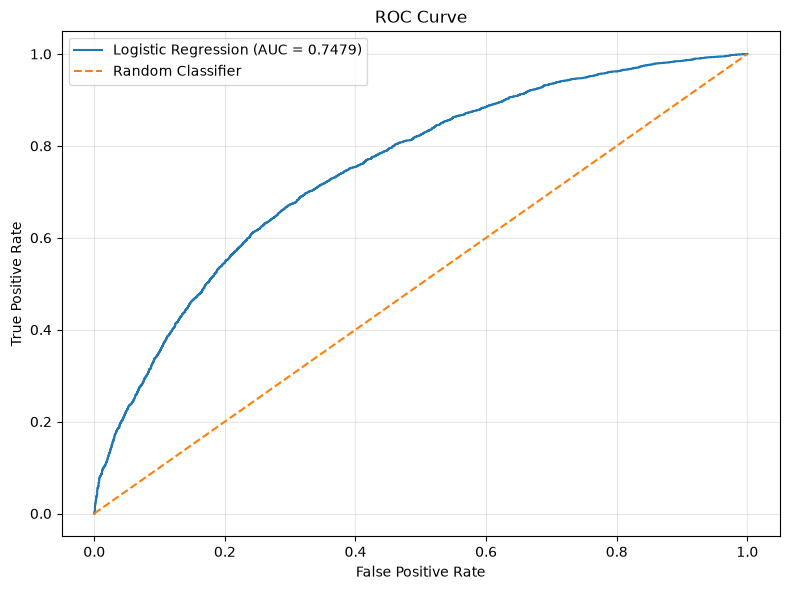

In [73]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [74]:
from tensorflow import keras
from tensorflow.keras import layers

deep_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),

    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

deep_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        29,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,321 (157.50 KB)

 Trainable params: 40,321 (157.50 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
deep_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [76]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [77]:
history = deep_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6108 - auc: 0.6481 - loss: 0.6646 - precision: 0.6107 - recall: 0.6142 - val_accuracy: 0.6650 - val_auc: 0.7244 - val_loss: 0.6155 - val_precision: 0.6499 - val_recall: 0.7070
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6601 - auc: 0.7172 - loss: 0.6198 - precision: 0.6605 - recall: 0.6609 - val_accuracy: 0.6808 - val_auc: 0.7381 - val_loss: 0.6035 - val_precision: 0.6728 - val_recall: 0.6966
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6714 - auc: 0.7312 - loss: 0.6097 - precision: 0.6727 - recall: 0.6694 - val_accuracy: 0.6811 - val_auc: 0.7415 - val_loss: 0.6010 - val_precision: 0.6723 - val_recall: 0.6997
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6810 - auc: 0.7422 - loss: 0.5995 - precision: 0.6842 - recall: 0.6739 - val_accuracy: 0.6835 - val_auc: 0.7420 - val_loss: 0.6000 - val_precision: 0.6762 - val_recall: 0.6974
Epoch 5/30
125/125 ━━━━━━━━━━━━━

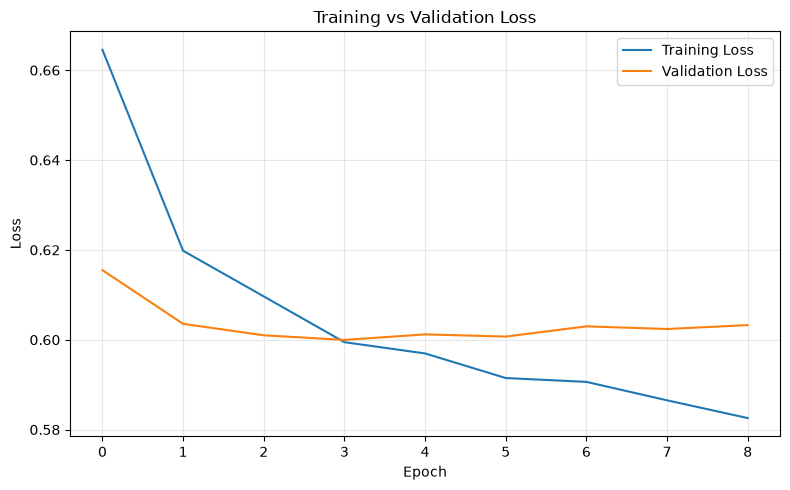

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

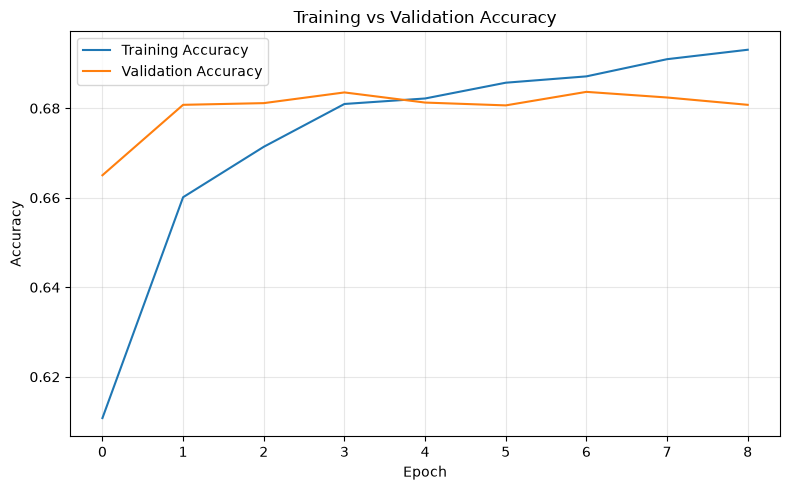

In [79]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

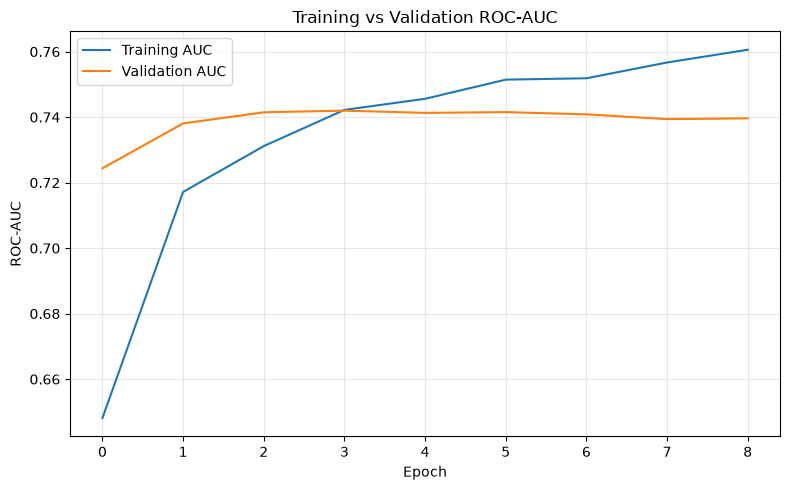

In [80]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["auc"],
    label="Training AUC"
)

plt.plot(
    history.history["val_auc"],
    label="Validation AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
import numpy as np

print("========== MODEL DIAGNOSTICS ==========")

print("\n1. MODEL TYPE")
print(type(model))

print("\n2. DATA TYPES")
print("X_train type:", type(X_train))
print("X_test type:", type(X_test))

print("\n3. SHAPES")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\n4. DATA RANGE")

X_train_array = np.asarray(X_train)
X_test_array = np.asarray(X_test)

print("X_train min:", np.nanmin(X_train_array))
print("X_train max:", np.nanmax(X_train_array))
print("X_train mean:", np.nanmean(X_train_array))
print("X_train std :", np.nanstd(X_train_array))

print("\nX_test min:", np.nanmin(X_test_array))
print("X_test max:", np.nanmax(X_test_array))
print("X_test mean:", np.nanmean(X_test_array))
print("X_test std :", np.nanstd(X_test_array))

print("\n5. MODEL COEFFICIENTS")

if hasattr(model, "coef_"):
    print("Coefficient shape:", model.coef_.shape)
    print("Minimum coefficient:", model.coef_.min())
    print("Maximum coefficient:", model.coef_.max())
    print("Mean absolute coefficient:", np.mean(np.abs(model.coef_)))
    print("Maximum absolute coefficient:", np.max(np.abs(model.coef_)))

if hasattr(model, "intercept_"):
    print("Intercept:", model.intercept_)

print("\n6. DECISION FUNCTION")

decision_scores = model.decision_function(X_test)

print("Minimum decision score:", decision_scores.min())
print("Maximum decision score:", decision_scores.max())
print("Mean decision score:", decision_scores.mean())
print("Std decision score:", decision_scores.std())

print("\nFirst 20 decision scores:")
print(decision_scores[:20])

print("\n7. PROBABILITIES")

probs = model.predict_proba(X_test)[:, 1]

print("Unique probabilities:", len(np.unique(probs)))
print("Minimum probability:", probs.min())
print("Maximum probability:", probs.max())

print("\nFirst 20 probabilities:")
print(probs[:20])

print("\n========================================")

========== MODEL DIAGNOSTICS ==========

1. MODEL TYPE
<class 'sklearn.linear_model._logistic.LogisticRegression'>

2. DATA TYPES
X_train type: <class 'pandas.DataFrame'>
X_test type: <class 'pandas.DataFrame'>

3. SHAPES
X_train: (39720, 233)
X_test : (9930, 233)

4. DATA RANGE
X_train min: -25169.0
X_train max: 117000000.0
X_train mean: 5675.516192367059
X_train std : 73586.09412974583

X_test min: -25180.0
X_test max: 2931660.0
X_test mean: 5664.706393617409
X_test std : 62810.65854528502

5. MODEL COEFFICIENTS
Coefficient shape: (1, 233)
Minimum coefficient: -1.4879584321017267
Maximum coefficient: 3.6501387668680727
Mean absolute coefficient: 0.09542143241669399
Maximum absolute coefficient: 3.6501387668680727
Intercept: [0.00046703]

6. DECISION FUNCTION
Minimum decision score: -287534.824898136
Maximum decision score: 1600114.805476123
Mean decision score: 229455.29175987953
Std decision score: 481388.7135645443

First 20 decision scores:
[  26246.29328805   21450.85825332   647

c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [82]:
import numpy as np

print("========== LOGISTIC REGRESSION DIAGNOSTIC ==========")

# Coefficients
print("\nMODEL COEFFICIENTS")
print("Coefficient shape:", model.coef_.shape)
print("Min coefficient:", np.min(model.coef_))
print("Max coefficient:", np.max(model.coef_))
print("Mean absolute coefficient:", np.mean(np.abs(model.coef_)))
print("Max absolute coefficient:", np.max(np.abs(model.coef_)))
print("Intercept:", model.intercept_)

# Decision scores
decision_scores = model.decision_function(X_test)

print("\nDECISION SCORES")
print("Min:", decision_scores.min())
print("Max:", decision_scores.max())
print("Mean:", decision_scores.mean())
print("Std:", decision_scores.std())

print("\nFirst 20 decision scores:")
print(np.round(decision_scores[:20], 4))

# Probabilities
probs = model.predict_proba(X_test)[:, 1]

print("\nPROBABILITIES")
print("Unique probabilities:", len(np.unique(probs)))
print("Min:", probs.min())
print("Max:", probs.max())

print("\nProbability distribution:")
print("Exactly 0:", np.sum(probs == 0))
print("Exactly 1:", np.sum(probs == 1))
print("Between 0 and 1:", np.sum((probs > 0) & (probs < 1)))

print("\n====================================================")

========== LOGISTIC REGRESSION DIAGNOSTIC ==========

MODEL COEFFICIENTS
Coefficient shape: (1, 233)
Min coefficient: -1.4879584321017267
Max coefficient: 3.6501387668680727
Mean absolute coefficient: 0.09542143241669399
Max absolute coefficient: 3.6501387668680727
Intercept: [0.00046703]

DECISION SCORES
Min: -287534.824898136
Max: 1600114.805476123
Mean: 229455.29175987953
Std: 481388.7135645443

First 20 decision scores:
[  26246.2933   21450.8583   64733.474    25145.8811   41703.1196
 1395909.0228   36000.7589   -8865.4779 1444669.8071   88306.0435
  -16954.7676   91181.6854   71809.7067   39947.7576   35484.5634
  -10667.7746   20317.9472   97186.6882  -35917.1751   86848.7081]

PROBABILITIES
Unique probabilities: 22
Min: 0.0
Max: 1.0

Probability distribution:
Exactly 0: 3011
Exactly 1: 6899
Between 0 and 1: 20



c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [83]:
print("Top 20 features by maximum absolute value:")
print(
    X_train.abs()
    .max()
    .sort_values(ascending=False)
    .head(20)
)

Top 20 features by maximum absolute value:
AMT_INCOME_TOTAL              117000000.0
AMT_CREDIT                      4027680.0
AMT_GOODS_PRICE                 3600000.0
DAYS_EMPLOYED                    365243.0
AMT_ANNUITY                      213291.0
DAYS_BIRTH                        25169.0
DAYS_REGISTRATION                 22928.0
DAYS_ID_PUBLISH                    6274.0
DAYS_LAST_PHONE_CHANGE             4070.0
OWN_CAR_AGE                          91.0
OBS_30_CNT_SOCIAL_CIRCLE             30.0
OBS_60_CNT_SOCIAL_CIRCLE             29.0
HOUR_APPR_PROCESS_START              23.0
AMT_REQ_CREDIT_BUREAU_YEAR           22.0
CNT_FAM_MEMBERS                      20.0
CNT_CHILDREN                         19.0
AMT_REQ_CREDIT_BUREAU_QRT            19.0
AMT_REQ_CREDIT_BUREAU_MON            17.0
AMT_REQ_CREDIT_BUREAU_WEEK            8.0
DEF_30_CNT_SOCIAL_CIRCLE              6.0
dtype: float64


In [84]:
print("\nTop 20 features by standard deviation:")
print(
    X_train.std()
    .sort_values(ascending=False)
    .head(20)
)


Top 20 features by standard deviation:
AMT_INCOME_TOTAL               593420.482869
AMT_CREDIT                     378950.719552
AMT_GOODS_PRICE                345397.166425
DAYS_EMPLOYED                  132315.650989
AMT_ANNUITY                     13607.548620
DAYS_BIRTH                       4329.816147
DAYS_REGISTRATION                3418.705880
DAYS_ID_PUBLISH                  1514.936728
DAYS_LAST_PHONE_CHANGE            799.397240
OWN_CAR_AGE                         7.136373
HOUR_APPR_PROCESS_START             3.277974
OBS_30_CNT_SOCIAL_CIRCLE            2.349419
OBS_60_CNT_SOCIAL_CIRCLE            2.328239
AMT_REQ_CREDIT_BUREAU_YEAR          1.752387
CNT_FAM_MEMBERS                     0.933522
CNT_CHILDREN                        0.745429
AMT_REQ_CREDIT_BUREAU_MON           0.743111
AMT_REQ_CREDIT_BUREAU_QRT           0.586575
REGION_RATING_CLIENT                0.511560
REGION_RATING_CLIENT_W_CITY         0.505747
dtype: float64


In [85]:
X_train_lr = X_train.copy()
X_test_lr = X_test.copy()

print("Original training shape:", X_train_lr.shape)
print("Original testing shape :", X_test_lr.shape)

# Remove customer ID because it is an identifier, not a
# meaningful predictive feature.
if 'SK_ID_CURR' in X_train_lr.columns:
    X_train_lr = X_train_lr.drop(columns=['SK_ID_CURR'])
    X_test_lr = X_test_lr.drop(columns=['SK_ID_CURR'])
    print("\nSK_ID_CURR removed.")

print("\nFinal training shape:", X_train_lr.shape)
print("Final testing shape :", X_test_lr.shape)

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Original training shape: (39720, 233)
Original testing shape : (9930, 233)

Final training shape: (39720, 233)
Final testing shape : (9930, 233)

Target shapes:
y_train: (39720,)
y_test : (9930,)


In [86]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler_lr = StandardScaler()

# IMPORTANT:
# Fit ONLY on training data.
X_train_scaled = scaler_lr.fit_transform(X_train_lr)

# Transform test data using the SAME scaler.
X_test_scaled = scaler_lr.transform(X_test_lr)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

print("\nTraining feature statistics after scaling:")
print("Mean:", np.mean(X_train_scaled))
print("Std :", np.std(X_train_scaled))

print("\nTest feature statistics:")
print("Mean:", np.mean(X_test_scaled))
print("Std :", np.std(X_test_scaled))

Scaled training shape: (39720, 233)
Scaled testing shape : (9930, 233)

Training feature statistics after scaling:
Mean: -3.6333437525242126e-17
Std : 0.9956989047964628

Test feature statistics:
Mean: 0.0008351874157534869
Std : 1.0086961938525507


In [87]:
from sklearn.linear_model import LogisticRegression

# Create a fresh Logistic Regression model
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train on scaled training features
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully.")
print("Model:", lr_model)

Logistic Regression trained successfully.
Model: LogisticRegression(max_iter=2000, random_state=42)


In [88]:
# ============================================================
# VERIFY DECISION SCORES
# ============================================================

decision_scores_lr = lr_model.decision_function(X_test_scaled)

print("========== SCALED MODEL DIAGNOSTIC ==========")

print("\nDecision scores:")
print("Minimum:", decision_scores_lr.min())
print("Maximum:", decision_scores_lr.max())
print("Mean:", decision_scores_lr.mean())
print("Std :", decision_scores_lr.std())

print("\nFirst 20 decision scores:")
print(np.round(decision_scores_lr[:20], 4))

print("\n==============================================")

========== SCALED MODEL DIAGNOSTIC ==========

Decision scores:
Minimum: -10.543042403635532
Maximum: 3.3489686867347532
Mean: 0.003516266164744662
Std : 1.0532318382902162

First 20 decision scores:
[ 0.5363  0.6158 -0.9416  0.476   0.7887 -0.7028 -0.1441 -0.507   0.231
  0.7693 -1.1107  1.255  -0.4993 -0.2684  0.8024  1.7884  1.6618  0.1389
 -0.0982 -0.0609]



In [89]:
# Generate probability predictions for the positive class
y_test_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Convert probabilities into binary predictions
threshold = 0.5
y_test_pred_lr = (y_test_prob_lr >= threshold).astype(int)

print("Number of test samples:", len(y_test_prob_lr))

print("\nNumber of unique predicted probabilities:",
      len(np.unique(y_test_prob_lr)))

print("\nProbability range:")
print("Min:", y_test_prob_lr.min())
print("Max:", y_test_prob_lr.max())

print("\nFirst 20 predicted probabilities:")
print(np.round(y_test_prob_lr[:20], 4))

print("\nFirst 20 predicted classes:")
print(y_test_pred_lr[:20])

Number of test samples: 9930

Number of unique predicted probabilities: 9930

Probability range:
Min: 2.6375664302840327e-05
Max: 0.966071047926943

First 20 predicted probabilities:
[0.6309 0.6493 0.2806 0.6168 0.6875 0.3312 0.464  0.3759 0.5575 0.6834
 0.2477 0.7782 0.3777 0.4333 0.6905 0.8567 0.8405 0.5347 0.4755 0.4848]

First 20 predicted classes:
[1 1 0 1 1 0 0 0 1 1 0 1 0 0 1 1 1 1 0 0]


In [90]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

accuracy_lr = accuracy_score(y_test, y_test_pred_lr)
precision_lr = precision_score(y_test, y_test_pred_lr)
recall_lr = recall_score(y_test, y_test_pred_lr)
f1_lr = f1_score(y_test, y_test_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_test_prob_lr)

print("================================================")
print("       LOGISTIC REGRESSION TEST EVALUATION")
print("================================================")

print(f"\nAccuracy  : {accuracy_lr:.4f}")
print(f"Precision : {precision_lr:.4f}")
print(f"Recall    : {recall_lr:.4f}")
print(f"Sensitivity: {recall_lr:.4f}")
print(f"F1-Score  : {f1_lr:.4f}")
print(f"ROC-AUC   : {roc_auc_lr:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr))

       LOGISTIC REGRESSION TEST EVALUATION

Accuracy  : 0.6856
Precision : 0.6860
Recall    : 0.6844
Sensitivity: 0.6844
F1-Score  : 0.6852
ROC-AUC   : 0.7479

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69      4965
           1       0.69      0.68      0.69      4965

    accuracy                           0.69      9930
   macro avg       0.69      0.69      0.69      9930
weighted avg       0.69      0.69      0.69      9930


Confusion Matrix:
[[3410 1555]
 [1567 3398]]


In [91]:
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

tn_lr, fp_lr, fn_lr, tp_lr = cm_lr.ravel()

print("Confusion Matrix Components")
print("============================")

print("True Negatives  (TN):", tn_lr)
print("False Positives (FP):", fp_lr)
print("False Negatives (FN):", fn_lr)
print("True Positives  (TP):", tp_lr)

print("\nSensitivity / Recall:",
      f"{recall_lr:.4f}")

print("Sensitivity:",
      f"{recall_lr * 100:.2f}%")

Confusion Matrix Components
True Negatives  (TN): 3410
False Positives (FP): 1555
False Negatives (FN): 1567
True Positives  (TP): 3398

Sensitivity / Recall: 0.6844
Sensitivity: 68.44%


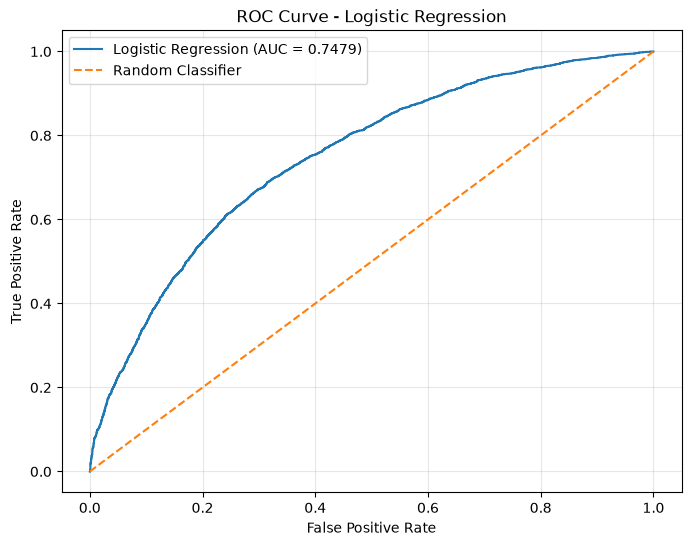

ROC-AUC Score: 0.7479


In [92]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_lr, tpr_lr, thresholds_lr = roc_curve(
    y_test,
    y_test_prob_lr
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print(f"ROC-AUC Score: {roc_auc_lr:.4f}")

In [93]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Generate Precision-Recall values
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_test_prob
)

# Calculate PR-AUC / Average Precision
pr_auc = average_precision_score(y_test, y_test_prob)

print("=" * 50)
print("PRECISION-RECALL EVALUATION")
print("=" * 50)
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

# Plot Precision-Recall curve
plt.figure(figsize=(10, 6))

plt.plot(
    recall,
    precision,
    label=f"Logistic Regression (PR-AUC = {pr_auc:.4f})"
)

# Baseline for balanced test set
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Random Classifier (Baseline = {baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'y_test_prob' is not defined

In [ ]:
import numpy as np
import pandas as pd

print("=" * 60)
print("LOGISTIC REGRESSION PROBABILITY DIAGNOSTIC")
print("=" * 60)

# 1. Model information
print("\n1. MODEL")
print(type(model))

# 2. Check feature matrices
print("\n2. DATA")
print("X_train type:", type(X_train))
print("X_test type :", type(X_test))
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

# 3. Generate probabilities directly from predict_proba
proba = model.predict_proba(X_test)[:, 1]

print("\n3. PROBABILITY STATISTICS")
print("Min:", np.min(proba))
print("Max:", np.max(proba))
print("Mean:", np.mean(proba))
print("Std :", np.std(proba))

print("\nNumber of unique probabilities:", len(np.unique(proba)))

# 4. Quantiles
print("\n4. PROBABILITY QUANTILES")

quantiles = np.quantile(
    proba,
    [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
)

for q, value in zip(
    [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100],
    quantiles
):
    print(f"{q:>3}% : {value:.10f}")

# 5. Count probability values
print("\n5. MOST COMMON PROBABILITIES")

prob_counts = pd.Series(proba).value_counts().head(20)

print(prob_counts)

# 6. Decision function
if hasattr(model, "decision_function"):
    scores = model.decision_function(X_test)

    print("\n6. DECISION SCORES")
    print("Min :", np.min(scores))
    print("Max :", np.max(scores))
    print("Mean:", np.mean(scores))
    print("Std :", np.std(scores))

# 7. Check for extreme probabilities
print("\n7. EXTREME PROBABILITY COUNTS")

print(
    "Exactly 0.0:",
    np.sum(proba == 0.0)
)

print(
    "Exactly 1.0:",
    np.sum(proba == 1.0)
)

print(
    "Between 0 and 0.01:",
    np.sum((proba > 0) & (proba < 0.01))
)

print(
    "Between 0.01 and 0.99:",
    np.sum((proba >= 0.01) & (proba <= 0.99))
)

print(
    "Between 0.99 and 1:",
    np.sum((proba > 0.99) & (proba < 1))
)

print("\n" + "=" * 60)
print("DIAGNOSTIC COMPLETE")
print("=" * 60)

LOGISTIC REGRESSION PROBABILITY DIAGNOSTIC

1. MODEL
<class 'sklearn.linear_model._logistic.LogisticRegression'>

2. DATA
X_train type: <class 'pandas.DataFrame'>
X_test type : <class 'pandas.DataFrame'>
X_train shape: (39720, 233)
X_test shape : (9930, 233)

3. PROBABILITY STATISTICS
Min: 0.0
Max: 1.0
Mean: 0.6950603723286115
Std : 0.46037660899603117

Number of unique probabilities: 22

4. PROBABILITY QUANTILES
  0% : 0.0000000000
  1% : 0.0000000000
  5% : 0.0000000000
 10% : 0.0000000000
 25% : 0.0000000000
 50% : 1.0000000000
 75% : 1.0000000000
 90% : 1.0000000000
 95% : 1.0000000000
 99% : 1.0000000000
100% : 1.0000000000

5. MOST COMMON PROBABILITIES
1.000000e+00     6899
0.000000e+00     3011
9.274604e-40        1
3.563177e-204       1
1.949090e-228       1
9.494981e-01        1
1.269932e-239       1
1.618714e-99        1
9.999992e-01        1
3.856836e-251       1
1.466540e-146       1
1.677701e-43        1
3.513246e-234       1
1.000000e+00        1
2.265820e-296       1
2.2

c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a properly scaled Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        random_state=42
    ))
])

# Train the model
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression pipeline trained successfully.")

Logistic Regression pipeline trained successfully.


In [ ]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nModel:")
print(logistic_pipeline)

Training shape: (39720, 233)
Testing shape: (9930, 233)

Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])


In [ ]:
# Generate probability predictions
y_test_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

# Generate class predictions
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("Number of test samples:", len(y_test_prob))
print("Number of unique predicted probabilities:", len(set(y_test_prob)))

print("\nProbability range:")
print("Min:", y_test_prob.min())
print("Max:", y_test_prob.max())

print("\nFirst 20 predicted probabilities:")
print(y_test_prob[:20])

print("\nFirst 20 predicted classes:")
print(y_test_pred[:20])

Number of test samples: 9930
Number of unique predicted probabilities: 9930

Probability range:
Min: 2.6375664302840327e-05
Max: 0.966071047926943

First 20 predicted probabilities:
[0.63094867 0.64926566 0.28058536 0.61679901 0.6875469  0.33118564
 0.46403596 0.37589813 0.55749183 0.68336196 0.24773321 0.77816228
 0.37770958 0.43330145 0.69048802 0.85673325 0.84047424 0.53468105
 0.47547301 0.48479216]

First 20 predicted classes:
[1 1 0 1 1 0 0 0 1 1 0 1 0 0 1 1 1 1 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("=" * 55)
print("SCALED LOGISTIC REGRESSION TEST EVALUATION")
print("=" * 55)

print(f"\nAccuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Sensitivity : {recall:.4f}")
print(f"F1-Score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

SCALED LOGISTIC REGRESSION TEST EVALUATION

Accuracy    : 0.6856
Precision   : 0.6860
Recall      : 0.6844
Sensitivity : 0.6844
F1-Score    : 0.6852
ROC-AUC     : 0.7479

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69      4965
           1       0.69      0.68      0.69      4965

    accuracy                           0.69      9930
   macro avg       0.69      0.69      0.69      9930
weighted avg       0.69      0.69      0.69      9930

Confusion Matrix:
[[3410 1555]
 [1567 3398]]


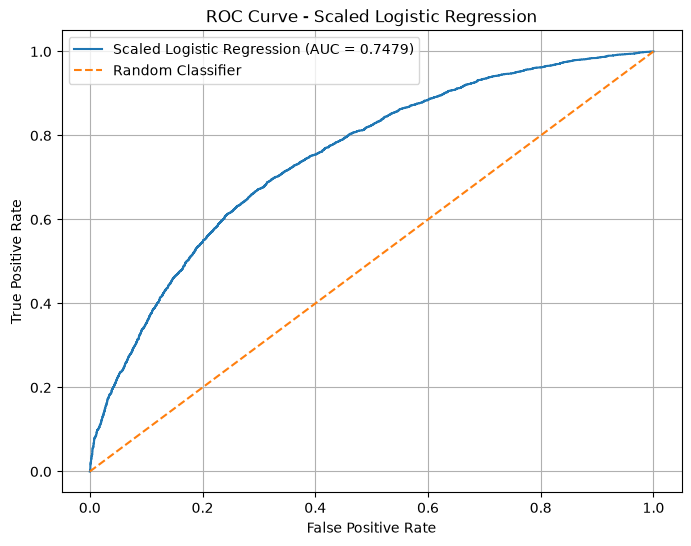

ROC-AUC Score: 0.7479


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Scaled Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Scaled Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

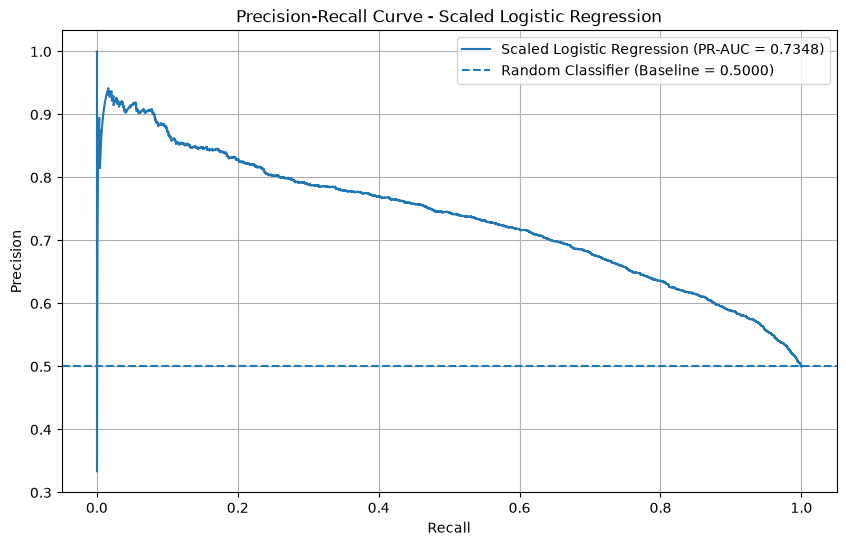

PR-AUC Score: 0.7348


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    y_test_prob
)

pr_auc = average_precision_score(y_test, y_test_prob)

plt.figure(figsize=(10, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Scaled Logistic Regression (PR-AUC = {pr_auc:.4f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label=f"Random Classifier (Baseline = {y_test.mean():.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Scaled Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

print(f"PR-AUC Score: {pr_auc:.4f}")

In [ ]:
print("=" * 55)
print("SCALED LOGISTIC REGRESSION PROBABILITY DIAGNOSTIC")
print("=" * 55)

print("\nModel:")
print(logistic_pipeline)

print("\nProbability Statistics:")
print("Min :", y_test_prob.min())
print("Max :", y_test_prob.max())
print("Mean:", y_test_prob.mean())
print("Std :", y_test_prob.std())

print("\nNumber of unique probabilities:")
print(len(set(y_test_prob)))

print("\nProbability Quantiles:")
print(np.quantile(
    y_test_prob,
    [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.0]
))

SCALED LOGISTIC REGRESSION PROBABILITY DIAGNOSTIC

Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

Probability Statistics:
Min : 2.6375664302840327e-05
Max : 0.966071047926943
Mean: 0.5009732583831379
Std : 0.21715170273003948

Number of unique probabilities:
9930

Probability Quantiles:
[2.63756643e-05 8.55821276e-02 1.53659864e-01 3.27866658e-01
 4.99225589e-01 6.76724357e-01 8.48850189e-01 9.13427982e-01
 9.66071048e-01]


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

In [ ]:
import pandas as pd
import numpy as np

print("=" * 60)
print("PHASE 2 — CORRECT EVALUATION")
print("=" * 60)

print("\nOriginal dataset:")
print("Shape:", df.shape)

print("\nTARGET distribution:")
print(df["TARGET"].value_counts())

print("\nTARGET percentage:")
print(df["TARGET"].value_counts(normalize=True) * 100)

PHASE 2 — CORRECT EVALUATION

Original dataset:
Shape: (307511, 122)

TARGET distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

TARGET percentage:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

# Stratified split BEFORE any balancing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("=" * 60)
print("NATURAL TRAIN/TEST SPLIT")
print("=" * 60)

print("\nTraining shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)

print("\nTraining TARGET distribution:")
print(y_train.value_counts())

print("\nTraining TARGET percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting TARGET distribution:")
print(y_test.value_counts())

print("\nTesting TARGET percentage:")
print(y_test.value_counts(normalize=True) * 100)

NATURAL TRAIN/TEST SPLIT

Training shape: (246008, 121)
Testing shape: (61503, 121)

Training TARGET distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Training TARGET percentage:
TARGET
0    91.927092
1     8.072908
Name: proportion, dtype: float64

Testing TARGET distribution:
TARGET
0    56538
1     4965
Name: count, dtype: int64

Testing TARGET percentage:
TARGET
0    91.927223
1     8.072777
Name: proportion, dtype: float64


In [ ]:
# Calculate missing percentage using TRAINING data only
missing_percentage = X_train_raw.isnull().mean() * 100

# Columns with >= 50% missing values
high_missing_cols = missing_percentage[
    missing_percentage >= 50
].index.tolist()

print("=" * 60)
print("HIGH-MISSING-VALUE FEATURE ANALYSIS")
print("=" * 60)

print("\nNumber of columns with >=50% missing values:",
      len(high_missing_cols))

print("\nColumns to remove:")

for col in high_missing_cols:
    print(
        f"{col:<40} "
        f"{missing_percentage[col]:.2f}%"
    )

HIGH-MISSING-VALUE FEATURE ANALYSIS

Number of columns with >=50% missing values: 41

Columns to remove:
OWN_CAR_AGE                              66.02%
EXT_SOURCE_1                             56.34%
APARTMENTS_AVG                           50.70%
BASEMENTAREA_AVG                         58.47%
YEARS_BUILD_AVG                          66.48%
COMMONAREA_AVG                           69.84%
ELEVATORS_AVG                            53.26%
ENTRANCES_AVG                            50.31%
FLOORSMIN_AVG                            67.85%
LANDAREA_AVG                             59.34%
LIVINGAPARTMENTS_AVG                     68.34%
LIVINGAREA_AVG                           50.19%
NONLIVINGAPARTMENTS_AVG                  69.40%
NONLIVINGAREA_AVG                        55.13%
APARTMENTS_MODE                          50.70%
BASEMENTAREA_MODE                        58.47%
YEARS_BUILD_MODE                         66.48%
COMMONAREA_MODE                          69.84%
ELEVATORS_MODE                 

In [ ]:
X_train = X_train_raw.drop(columns=high_missing_cols)
X_test = X_test_raw.drop(columns=high_missing_cols)

print("=" * 60)
print("AFTER HIGH-MISSING-COLUMN REMOVAL")
print("=" * 60)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

AFTER HIGH-MISSING-COLUMN REMOVAL

X_train shape: (246008, 80)
X_test shape: (61503, 80)


In [ ]:
X_train = X_train_raw.drop(columns=high_missing_cols)
X_test = X_test_raw.drop(columns=high_missing_cols)

print("=" * 60)
print("AFTER HIGH-MISSING-COLUMN REMOVAL")
print("=" * 60)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

AFTER HIGH-MISSING-COLUMN REMOVAL

X_train shape: (246008, 80)
X_test shape: (61503, 80)


In [ ]:
from sklearn.utils import resample

# Combine training data and target
train_data = X_train.copy()
train_data["TARGET"] = y_train.values

# Separate classes
train_class_0 = train_data[
    train_data["TARGET"] == 0
]

train_class_1 = train_data[
    train_data["TARGET"] == 1
]

# Undersample majority class to minority class size
train_class_0_balanced = resample(
    train_class_0,
    replace=False,
    n_samples=len(train_class_1),
    random_state=42
)

# Combine balanced classes
train_balanced = pd.concat(
    [
        train_class_0_balanced,
        train_class_1
    ]
)

# Shuffle
train_balanced = train_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Separate X and y
X_train_balanced = train_balanced.drop(
    columns=["TARGET"]
)

y_train_balanced = train_balanced["TARGET"]

print("=" * 60)
print("TRAINING DATA BALANCING")
print("=" * 60)

print("\nOriginal training distribution:")
print(y_train.value_counts())

print("\nBalanced training distribution:")
print(y_train_balanced.value_counts())

print("\nBalanced training shape:")
print(X_train_balanced.shape)

TRAINING DATA BALANCING

Original training distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Balanced training distribution:
TARGET
1    19860
0    19860
Name: count, dtype: int64

Balanced training shape:
(39720, 80)


In [ ]:
# Identify numerical and categorical features
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("=" * 60)
print("FEATURE TYPES")
print("=" * 60)

print(f"\nNumerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

FEATURE TYPES

Numerical features: 67
Categorical features: 13

Numerical columns:
['SK_ID_CURR', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'YEARS_BEGINEXPLUATATION_AVG', 'FLOORSMAX_AVG', 'YEARS_BEGINEXPLUATATION_MODE', 'FLOORSMAX_MODE', 'YEARS_BEGINEXPLUATATION_MEDI', 'FLOORSMAX_MEDI', 'TOTALAREA_MODE', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUM

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [ ]:
X_train_processed = preprocessor.fit_transform(
    X_train_balanced
)

X_test_processed = preprocessor.transform(
    X_test
)

print("=" * 60)
print("PREPROCESSING COMPLETE")
print("=" * 60)

print("\nTraining processed shape:",
      X_train_processed.shape)

print("Testing processed shape:",
      X_test_processed.shape)

print(
    "\nRemaining NaN values in training:",
    np.isnan(X_train_processed).sum()
)

print(
    "Remaining NaN values in testing:",
    np.isnan(X_test_processed).sum()
)

PREPROCESSING COMPLETE

Training processed shape: (39720, 190)
Testing processed shape: (61503, 190)

Remaining NaN values in training: 0
Remaining NaN values in testing: 0


In [ ]:
print("=" * 60)
print("FITTING PREPROCESSOR")
print("=" * 60)

X_train_processed = preprocessor.fit_transform(
    X_train_balanced
)

X_test_processed = preprocessor.transform(
    X_test
)

print("\nTraining processed shape:",
      X_train_processed.shape)

print("Testing processed shape:",
      X_test_processed.shape)

print(
    "\nRemaining NaN values in training:",
    np.isnan(X_train_processed).sum()
)

print(
    "Remaining NaN values in testing:",
    np.isnan(X_test_processed).sum()
)

FITTING PREPROCESSOR

Training processed shape: (39720, 190)
Testing processed shape: (61503, 190)

Remaining NaN values in training: 0
Remaining NaN values in testing: 0


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

print("=" * 60)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 60)

model.fit(
    X_train_processed,
    y_train_balanced
)

print("\nModel trained successfully.")

TRAINING LOGISTIC REGRESSION

Model trained successfully.


In [ ]:
# Generate probability predictions
y_test_prob = model.predict_proba(
    X_test_processed
)[:, 1]

# Generate binary predictions
y_test_pred = (
    y_test_prob >= 0.5
).astype(int)

print("=" * 60)
print("NATURAL TEST SET PREDICTIONS")
print("=" * 60)

print("\nNumber of test samples:",
      len(y_test))

print("\nFirst 20 predicted probabilities:")
print(y_test_prob[:20])

print("\nFirst 20 predicted classes:")
print(y_test_pred[:20])

print("\nActual test labels:")
print(y_test.values[:20])

NATURAL TEST SET PREDICTIONS

Number of test samples: 61503

First 20 predicted probabilities:
[0.325556   0.39326342 0.78180889 0.67309885 0.63167119 0.64866339
 0.09859697 0.07399826 0.8346476  0.39984882 0.22860716 0.53799377
 0.20296946 0.41955648 0.4855991  0.38588783 0.377849   0.24909302
 0.25668686 0.2032192 ]

First 20 predicted classes:
[0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0]

Actual test labels:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]


In [ ]:
# Generate probability predictions
y_test_prob = model.predict_proba(
    X_test_processed
)[:, 1]

# Generate binary predictions
y_test_pred = (
    y_test_prob >= 0.5
).astype(int)

print("=" * 60)
print("NATURAL TEST SET PREDICTIONS")
print("=" * 60)

print("\nNumber of test samples:",
      len(y_test))

print("\nFirst 20 predicted probabilities:")
print(y_test_prob[:20])

print("\nFirst 20 predicted classes:")
print(y_test_pred[:20])

print("\nActual test labels:")
print(y_test.values[:20])

NATURAL TEST SET PREDICTIONS

Number of test samples: 61503

First 20 predicted probabilities:
[0.325556   0.39326342 0.78180889 0.67309885 0.63167119 0.64866339
 0.09859697 0.07399826 0.8346476  0.39984882 0.22860716 0.53799377
 0.20296946 0.41955648 0.4855991  0.38588783 0.377849   0.24909302
 0.25668686 0.2032192 ]

First 20 predicted classes:
[0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0]

Actual test labels:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)

print("=" * 60)
print("LOGISTIC REGRESSION — NATURAL TEST SET EVALUATION")
print("=" * 60)

print(f"\nAccuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"Sensitivity  : {recall:.4f}")
print(f"F1-Score     : {f1:.4f}")
print(f"ROC-AUC      : {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
cm = confusion_matrix(
    y_test,
    y_test_pred
)

print(cm)

LOGISTIC REGRESSION — NATURAL TEST SET EVALUATION

Accuracy     : 0.6847
Precision    : 0.1587
Recall       : 0.6753
Sensitivity  : 0.6753
F1-Score     : 0.2570
ROC-AUC      : 0.7450

Classification Report:
              precision    recall  f1-score   support

           0     0.9601    0.6855    0.7999     56538
           1     0.1587    0.6753    0.2570      4965

    accuracy                         0.6847     61503
   macro avg     0.5594    0.6804    0.5284     61503
weighted avg     0.8954    0.6847    0.7561     61503


Confusion Matrix:
[[38758 17780]
 [ 1612  3353]]


In [ ]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred
).ravel()

print("=" * 60)
print("CONFUSION MATRIX COMPONENTS")
print("=" * 60)

print(f"\nTrue Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

print("\nSensitivity / Recall:")
print(f"{tp / (tp + fn):.4f}")

print(f"{tp / (tp + fn) * 100:.2f}%")

CONFUSION MATRIX COMPONENTS

True Negatives  (TN): 38758
False Positives (FP): 17780
False Negatives (FN): 1612
True Positives  (TP): 3353

Sensitivity / Recall:
0.6753
67.53%


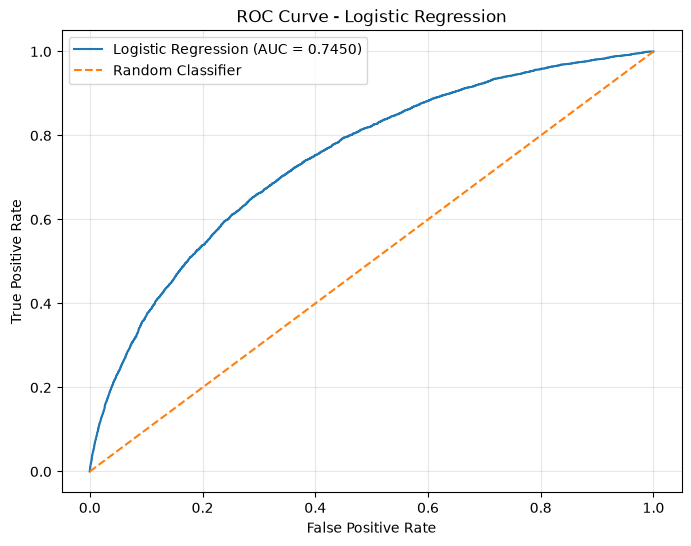

ROC-AUC Score: 0.7450


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_test_prob
)

roc_auc_value = auc(
    fpr,
    tpr
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print(f"ROC-AUC Score: {roc_auc_value:.4f}")

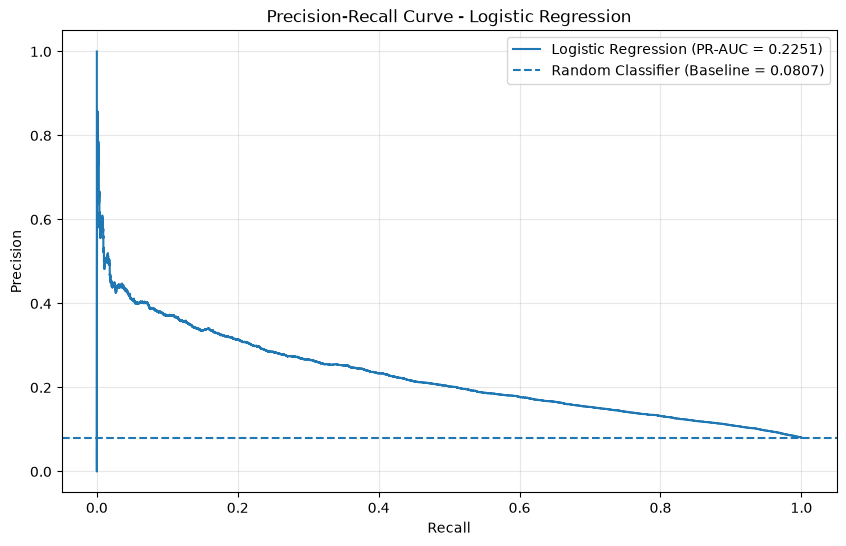

PR-AUC Score: 0.2251
Baseline Positive Rate: 0.0807


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test,
    y_test_prob
)

pr_auc = average_precision_score(
    y_test,
    y_test_prob
)

baseline = y_test.mean()

plt.figure(figsize=(10, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Logistic Regression (PR-AUC = {pr_auc:.4f})"
)

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Random Classifier (Baseline = {baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print(f"PR-AUC Score: {pr_auc:.4f}")
print(f"Baseline Positive Rate: {baseline:.4f}")

In [ ]:
print("=" * 60)
print("PROBABILITY DIAGNOSTIC")
print("=" * 60)

print("\nMinimum probability:",
      y_test_prob.min())

print("Maximum probability:",
      y_test_prob.max())

print("Mean probability:",
      y_test_prob.mean())

print("Standard deviation:",
      y_test_prob.std())

print("\nNumber of unique probabilities:",
      len(np.unique(y_test_prob)))

print("\nProbability quantiles:")

quantiles = np.quantile(
    y_test_prob,
    [0, 0.01, 0.05, 0.10, 0.25,
     0.50, 0.75, 0.90, 0.95,
     0.99, 1.0]
)

print(quantiles)

PROBABILITY DIAGNOSTIC

Minimum probability: 7.72595973472751e-07
Maximum probability: 0.9778627199914169
Mean probability: 0.42496715102927096
Standard deviation: 0.1969341308044955

Number of unique probabilities: 61503

Probability quantiles:
[7.72595973e-07 8.63762591e-02 1.38466573e-01 1.78456180e-01
 2.68245705e-01 4.03486619e-01 5.65344609e-01 7.09476439e-01
 7.80078684e-01 8.75042689e-01 9.77862720e-01]


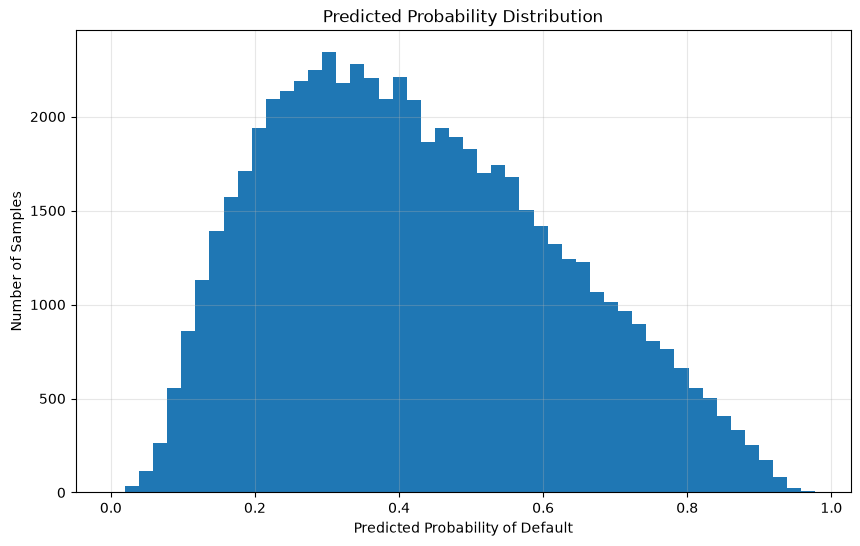

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    y_test_prob,
    bins=50
)

plt.xlabel("Predicted Probability of Default")
plt.ylabel("Number of Samples")
plt.title("Predicted Probability Distribution")

plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
import joblib
from pathlib import Path

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save model
joblib.dump(
    model,
    models_dir / "../models/logistic_regression_natural_test.pkl"
)

# Save preprocessor
joblib.dump(
    preprocessor,
    models_dir / "../models/logistic_regression_preprocessor.pkl"
)

# Save metadata
metadata = {
    "model": "Logistic Regression",
    "random_state": 42,
    "test_size": 0.20,
    "training_balanced": True,
    "testing_balanced": False,
    "high_missing_threshold": 50,
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "pr_auc": pr_auc
}

joblib.dump(
    metadata,
    models_dir / "../models/logistic_regression_natural_test_metadata.pkl"
)

print("Model, preprocessor, and metadata saved successfully.")

Model, preprocessor, and metadata saved successfully.


In [ ]:
print("=" * 60)
print("PHASE 3 - MODEL COMPARISON & OPTIMIZATION")
print("=" * 60)

print("\nTraining data:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTest data - DO NOT TOUCH DURING PHASE 3:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTraining target percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nTest target percentages:")
print(y_test.value_counts(normalize=True) * 100)

PHASE 3 - MODEL COMPARISON & OPTIMIZATION

Training data:
X_train shape: (246008, 80)
y_train shape: (246008,)

Test data - DO NOT TOUCH DURING PHASE 3:
X_test shape: (61503, 80)
y_test shape: (61503,)

Training target distribution:
TARGET
0    226148
1     19860
Name: count, dtype: int64

Training target percentages:
TARGET
0    91.927092
1     8.072908
Name: proportion, dtype: float64

Test target distribution:
TARGET
0    56538
1     4965
Name: count, dtype: int64

Test target percentages:
TARGET
0    91.927223
1     8.072777
Name: proportion, dtype: float64


In [ ]:
print("=" * 60)
print("PHASE 3 DATA TYPE CHECK")
print("=" * 60)

print("\nX_train shape:", X_train.shape)

print("\nData types:")
print(X_train.dtypes.value_counts())

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)

print("\nExample categorical values:")
for col in categorical_features[:10]:
    print(f"{col}: {X_train[col].dropna().unique()[:5]}")

PHASE 3 DATA TYPE CHECK

X_train shape: (246008, 80)

Data types:
int64      40
float64    27
str        13
Name: count, dtype: int64

Number of numerical features: 67
Number of categorical features: 13

Categorical features:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'EMERGENCYSTATE_MODE']

Example categorical values:
NAME_CONTRACT_TYPE: <StringArray>
['Cash loans', 'Revolving loans']
Length: 2, dtype: str
CODE_GENDER: <StringArray>
['F', 'M', 'XNA']
Length: 3, dtype: str
FLAG_OWN_CAR: <StringArray>
['N', 'Y']
Length: 2, dtype: str
FLAG_OWN_REALTY: <StringArray>
['N', 'Y']
Length: 2, dtype: str
NAME_TYPE_SUITE: <StringArray>
['Unaccompanied', 'Spouse, partner', 'Family', 'Other_B', 'Children']
Length: 5, dtype: str
NAME_INCOME_TYPE: <StringArray>
['Commercial associate', 'Working', '

In [ ]:
from sklearn.model_selection import train_test_split

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Training subset:", X_train_model.shape)
print("Validation subset:", X_val.shape)

print("\nTraining target distribution:")
print(y_train_model.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

Training subset: (196806, 80)
Validation subset: (49202, 80)

Training target distribution:
TARGET
0    180918
1     15888
Name: count, dtype: int64

Validation target distribution:
TARGET
0    45230
1     3972
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=3000,
            random_state=42
        )
    )
])

lr_model.fit(
    X_train_model,
    y_train_model
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [ ]:
X_train_transformed = lr_model.named_steps[
    "preprocessor"
].transform(X_train_model)

print("Original feature count:", X_train_model.shape[1])
print("Transformed feature count:", X_train_transformed.shape[1])
print("Transformed shape:", X_train_transformed.shape)

Original feature count: 80
Transformed feature count: 193
Transformed shape: (196806, 193)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

y_val_prob = lr_model.predict_proba(X_val)[:, 1]

y_val_pred = (
    y_val_prob >= 0.5
).astype(int)

print("=" * 60)
print("LOGISTIC REGRESSION - VALIDATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision : {precision_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_val, y_val_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_val, y_val_prob):.4f}")

LOGISTIC REGRESSION - VALIDATION
Accuracy  : 0.9193
Precision : 0.4950
Recall    : 0.0126
F1-Score  : 0.0246
ROC-AUC   : 0.7387
PR-AUC    : 0.2147


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    X_train_model,
    y_train_model
)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [ ]:
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

y_val_pred_rf = (
    y_val_prob_rf >= 0.5
).astype(int)

print("=" * 60)
print("RANDOM FOREST - VALIDATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Precision : {precision_score(y_val, y_val_pred_rf, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_val, y_val_pred_rf, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(y_val, y_val_pred_rf, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_val, y_val_prob_rf):.4f}")
print(f"PR-AUC    : {average_precision_score(y_val, y_val_prob_rf):.4f}")

RANDOM FOREST - VALIDATION
Accuracy  : 0.9193
Precision : 1.0000
Recall    : 0.0005
F1-Score  : 0.0010
ROC-AUC   : 0.7230
PR-AUC    : 0.2116


In [ ]:
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1": f1_score(y_val, y_val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob),
        "PR-AUC": average_precision_score(y_val, y_val_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_val, y_val_pred_rf),
        "Precision": precision_score(y_val, y_val_pred_rf, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred_rf, zero_division=0),
        "F1": f1_score(y_val, y_val_pred_rf, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob_rf),
        "PR-AUC": average_precision_score(y_val, y_val_prob_rf)
    }
])

print("=" * 90)
print("PHASE 3 MODEL COMPARISON")
print("=" * 90)

print(
    comparison
    .sort_values("PR-AUC", ascending=False)
    .to_string(index=False)
)

PHASE 3 MODEL COMPARISON
              Model  Accuracy  Precision   Recall       F1  ROC-AUC   PR-AUC
Logistic Regression  0.919251    0.49505 0.012588 0.024552 0.738716 0.214704
      Random Forest  0.919312    1.00000 0.000504 0.001007 0.722962 0.211586


In [ ]:
import numpy as np

# Logistic Regression
lr_prob = lr_model.predict_proba(X_val)[:, 1]

print("\nLOGISTIC REGRESSION")
print("-" * 40)

print("Minimum probability:", lr_prob.min())
print("Maximum probability:", lr_prob.max())
print("Mean probability:", lr_prob.mean())
print("Median probability:", np.median(lr_prob))

print("\nProbability quantiles:")
print(np.quantile(
    lr_prob,
    [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
))

print("\nPredictions at threshold 0.5:")
print(pd.Series(
    (lr_prob >= 0.5).astype(int)
).value_counts())

# Random Forest
rf_prob = rf_model.predict_proba(X_val)[:, 1]

print("\n\nRANDOM FOREST")
print("-" * 40)

print("Minimum probability:", rf_prob.min())
print("Maximum probability:", rf_prob.max())
print("Mean probability:", rf_prob.mean())
print("Median probability:", np.median(rf_prob))

print("\nProbability quantiles:")
print(np.quantile(
    rf_prob,
    [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
))

print("\nPredictions at threshold 0.5:")
print(pd.Series(
    (rf_prob >= 0.5).astype(int)
).value_counts())


LOGISTIC REGRESSION
----------------------------------------
Minimum probability: 1.1636488418809286e-16
Maximum probability: 0.717335058585886
Mean probability: 0.08125312722599533
Median probability: 0.056487815332628394

Probability quantiles:
[1.16364884e-16 8.64075039e-03 1.46764767e-02 1.94883758e-02
 3.15951558e-02 5.64878153e-02 1.03353090e-01 1.75819791e-01
 2.35786967e-01 3.76892511e-01 7.17335059e-01]

Predictions at threshold 0.5:
0    49101
1      101
Name: count, dtype: int64


RANDOM FOREST
----------------------------------------
Minimum probability: 0.0
Maximum probability: 0.5237547503331816
Mean probability: 0.08586030632433057
Median probability: 0.06912657177072265

Probability quantiles:
[0.         0.0127104  0.02170297 0.02803975 0.04295251 0.06912657
 0.11207269 0.16805346 0.20792858 0.2899522  0.52375475]

Predictions at threshold 0.5:
0    49200
1        2
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (lr_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted_Positive_%": predictions.mean() * 100,
        "Precision": precision_score(
            y_val,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("=" * 80)
print("LOGISTIC REGRESSION THRESHOLD ANALYSIS")
print("=" * 80)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Predicted_Positive_%": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

LOGISTIC REGRESSION THRESHOLD ANALYSIS


,Threshold,Predicted_Positive_%,Precision,Recall,F1
0,0.05,55.43,0.1222,0.8389,0.2133
1,0.10,26.17,0.1778,0.5765,0.2718
2,0.15,13.66,0.2270,0.3839,0.2853
3,0.20,7.49,0.2705,0.2510,0.2604
4,0.25,4.25,0.3110,0.1639,0.2147
5,0.30,2.42,0.3476,0.1042,0.1604
6,0.35,1.44,0.3803,0.0680,0.1153
7,0.40,0.75,0.4005,0.0370,0.0678
8,0.45,0.39,0.4398,0.0211,0.0404
9,0.50,0.21,0.4950,0.0126,0.0246


In [ ]:
print("=" * 60)
print("VALIDATION TARGET CHECK")
print("=" * 60)

print(y_val.value_counts())
print()
print(y_val.value_counts(normalize=True))

VALIDATION TARGET CHECK
TARGET
0    45230
1     3972
Name: count, dtype: int64

TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

# Split the existing training data into:
# 80% actual training
# 20% validation

X_train_phase3, X_val_phase3, y_train_phase3, y_val_phase3 = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Training shape:", X_train_phase3.shape)
print("Validation shape:", X_val_phase3.shape)

print("\nTraining TARGET distribution:")
print(y_train_phase3.value_counts())

print("\nValidation TARGET distribution:")
print(y_val_phase3.value_counts())

Training shape: (196806, 80)
Validation shape: (49202, 80)

Training TARGET distribution:
TARGET
0    180918
1     15888
Name: count, dtype: int64

Validation TARGET distribution:
TARGET
0    45230
1     3972
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression


# ============================================================
# IDENTIFY FEATURE TYPES
# ============================================================

numerical_features = X_train_phase3.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_phase3.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


print("=" * 60)
print("FEATURE TYPE DETECTION")
print("=" * 60)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nFirst numerical features:")
print(numerical_features[:10])

print("\nFirst categorical features:")
print(categorical_features[:10])


# ============================================================
# NUMERICAL PIPELINE
# ============================================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# ============================================================
# CATEGORICAL PIPELINE
# ============================================================

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])


# ============================================================
# COMBINED PREPROCESSOR
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)


# ============================================================
# LOGISTIC REGRESSION PIPELINE
# ============================================================

lr_model_phase3 = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42,
            solver="liblinear"
        )
    )
])


# ============================================================
# TRAIN
# ============================================================

lr_model_phase3.fit(
    X_train_phase3,
    y_train_phase3
)

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION TRAINED SUCCESSFULLY")
print("=" * 60)

FEATURE TYPE DETECTION
Numerical features: 67
Categorical features: 13

First numerical features:
['SK_ID_CURR', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION']

First categorical features:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']

LOGISTIC REGRESSION TRAINED SUCCESSFULLY


In [ ]:
# ============================================================
# PHASE 3 — VALIDATION PROBABILITY GENERATION
# ============================================================

import numpy as np

# Generate probability of TARGET = 1
y_val_prob = lr_model_phase3.predict_proba(
    X_val_phase3
)[:, 1]

print("=" * 60)
print("VALIDATION PROBABILITY DIAGNOSTICS")
print("=" * 60)

print(f"\nValidation samples      : {len(y_val_prob)}")
print(f"Minimum probability     : {y_val_prob.min():.6f}")
print(f"Maximum probability     : {y_val_prob.max():.6f}")
print(f"Mean probability        : {y_val_prob.mean():.6f}")
print(f"Median probability      : {np.median(y_val_prob):.6f}")
print(f"Unique probabilities    : {len(np.unique(y_val_prob))}")

print("\nFirst 20 probabilities:")
print(np.round(y_val_prob[:20], 6))

print("\nFirst 20 actual labels:")
print(y_val_phase3.iloc[:20].to_numpy())

VALIDATION PROBABILITY DIAGNOSTICS

Validation samples      : 49202
Minimum probability     : 0.000000
Maximum probability     : 0.720813
Mean probability        : 0.081266
Median probability      : 0.056583
Unique probabilities    : 49202

First 20 probabilities:
[0.293725 0.08821  0.010526 0.028438 0.192857 0.06865  0.077157 0.072799
 0.063076 0.043652 0.016739 0.0092   0.407399 0.065713 0.168277 0.08334
 0.08845  0.120594 0.024332 0.068123]

First 20 actual labels:
[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]


In [ ]:
# ============================================================
# PHASE 3 — THRESHOLD OPTIMIZATION
# ============================================================

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

thresholds = np.arange(0.01, 1.00, 0.01)

for threshold in thresholds:

    y_val_pred = (
        y_val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted_Positive_%": y_val_pred.mean() * 100,
        "Accuracy": accuracy_score(
            y_val_phase3,
            y_val_pred
        ),
        "Precision": precision_score(
            y_val_phase3,
            y_val_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_phase3,
            y_val_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_val_phase3,
            y_val_pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Sort by F1
threshold_df_sorted = threshold_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("TOP 15 DECISION THRESHOLDS — VALIDATION SET")
print("=" * 80)

display(
    threshold_df_sorted.head(15)
)

TOP 15 DECISION THRESHOLDS — VALIDATION SET


,Threshold,Predicted_Positive_%,Accuracy,Precision,Recall,F1
0,0.15,13.649852,0.845088,0.228261,0.385952,0.286864
1,0.16,12.066583,0.856205,0.238673,0.356747,0.286003
2,0.14,15.363197,0.832507,0.217621,0.414149,0.285318
3,0.13,17.428153,0.817670,0.208513,0.450151,0.285008
4,0.12,19.952441,0.798524,0.197413,0.487915,0.281094
5,0.17,10.678428,0.865005,0.245908,0.325277,0.280078
6,0.11,22.830373,0.777184,0.188819,0.533988,0.278987
7,0.18,9.479289,0.872729,0.254503,0.298842,0.274896
8,0.10,26.181863,0.750457,0.177612,0.576032,0.271508
9,0.19,8.450876,0.879111,0.262386,0.274673,0.268389


In [ ]:
# ============================================================
# SELECT OPTIMAL THRESHOLD
# ============================================================

best_row = threshold_df_sorted.iloc[0]

best_threshold = float(
    best_row["Threshold"]
)

print("=" * 60)
print("OPTIMAL THRESHOLD")
print("=" * 60)

print(f"\nOptimal threshold : {best_threshold:.2f}")
print(f"Validation F1     : {best_row['F1']:.4f}")
print(f"Validation Recall : {best_row['Recall']:.4f}")
print(f"Validation Precision: {best_row['Precision']:.4f}")
print(f"Validation Accuracy: {best_row['Accuracy']:.4f}")

OPTIMAL THRESHOLD

Optimal threshold : 0.15
Validation F1     : 0.2869
Validation Recall : 0.3860
Validation Precision: 0.2283
Validation Accuracy: 0.8451


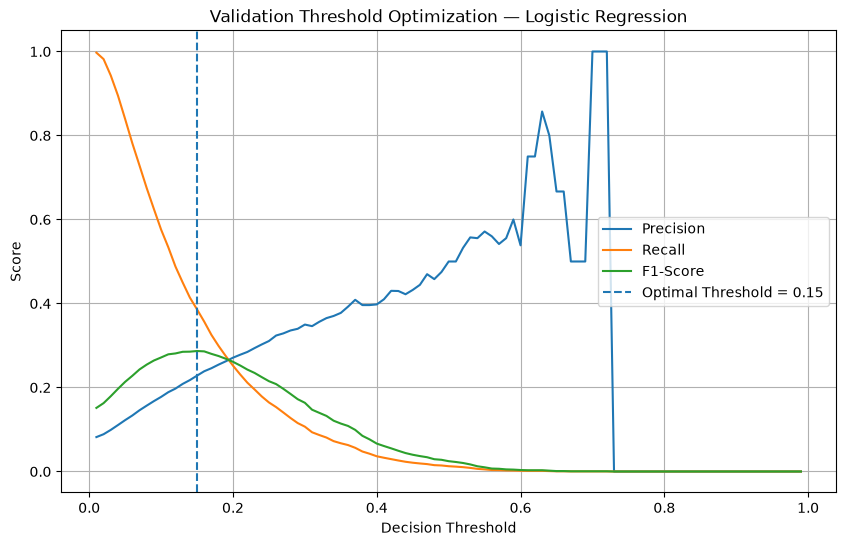

In [ ]:
# ============================================================
# THRESHOLD PERFORMANCE CURVES
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1-Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Optimal Threshold = {best_threshold:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Optimization — Logistic Regression")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# INSPECT NEARBY THRESHOLDS
# ============================================================

nearby = threshold_df[
    (
        threshold_df["Threshold"]
        >= best_threshold - 0.05
    )
    &
    (
        threshold_df["Threshold"]
        <= best_threshold + 0.05
    )
]

print("=" * 80)
print("THRESHOLDS AROUND OPTIMUM")
print("=" * 80)

display(nearby)

THRESHOLDS AROUND OPTIMUM


,Threshold,Predicted_Positive_%,Accuracy,Precision,Recall,F1
10,0.11,22.830373,0.777184,0.188819,0.533988,0.278987
11,0.12,19.952441,0.798524,0.197413,0.487915,0.281094
12,0.13,17.428153,0.817670,0.208513,0.450151,0.285008
13,0.14,15.363197,0.832507,0.217621,0.414149,0.285318
14,0.15,13.649852,0.845088,0.228261,0.385952,0.286864
15,0.16,12.066583,0.856205,0.238673,0.356747,0.286003
16,0.17,10.678428,0.865005,0.245908,0.325277,0.280078
17,0.18,9.479289,0.872729,0.254503,0.298842,0.274896
18,0.19,8.450876,0.879111,0.262386,0.274673,0.268389
19,0.20,7.507825,0.884883,0.270980,0.252014,0.261153


FINAL LOGISTIC REGRESSION EVALUATION

OPTIMAL VALIDATION THRESHOLD
Threshold : 0.15
Validation F1 : 0.2869

NATURAL TEST SET — FINAL RESULTS
Test samples       : 61,503
Positive cases     : 4,965
Positive prevalence: 8.0728%

Accuracy            : 0.8499
Precision           : 0.2388
Recall / Sensitivity: 0.3930
Specificity         : 0.8900
F1-Score            : 0.2971
ROC-AUC             : 0.7457
PR-AUC              : 0.2270

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9435    0.8900    0.9160     56538
           1     0.2388    0.3930    0.2971      4965

    accuracy                         0.8499     61503
   macro avg     0.5911    0.6415    0.6065     61503
weighted avg     0.8866    0.8499    0.8660     61503

CONFUSION MATRIX
[[50319  6219]
 [ 3014  1951]]

True Negatives  : 50,319
False Positives : 6,219
False Negatives : 3,014
True Positives  : 1,951


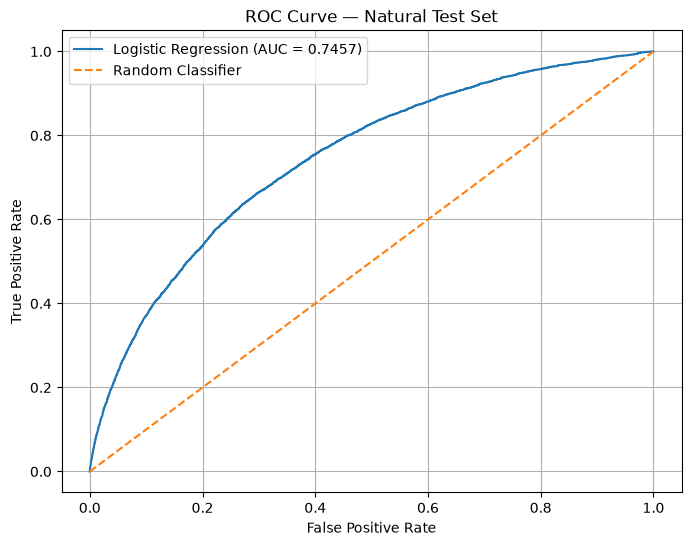

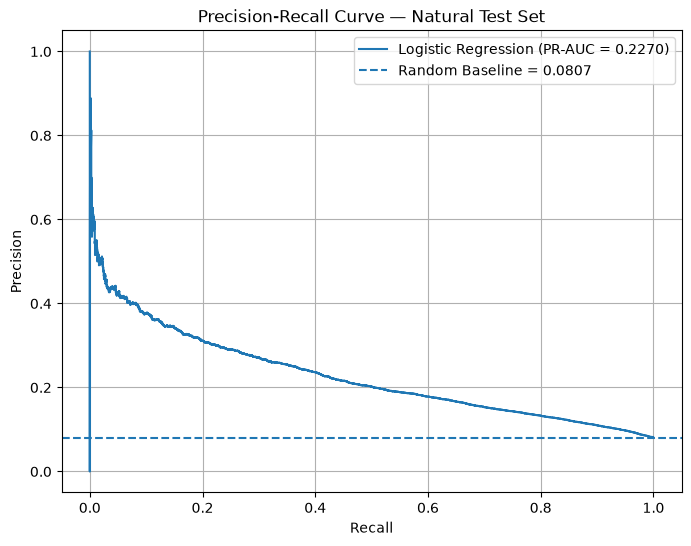


Final evaluation completed successfully.


In [ ]:
# ============================================================
# FINAL EVALUATION — NATURAL IMBALANCED TEST SET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

print("=" * 70)
print("FINAL LOGISTIC REGRESSION EVALUATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. VALIDATION PROBABILITIES
# ------------------------------------------------------------

y_val_prob = lr_model_phase3.predict_proba(
    X_val_phase3
)[:, 1]


# ------------------------------------------------------------
# 2. FIND BEST THRESHOLD USING VALIDATION SET ONLY
# ------------------------------------------------------------

thresholds = np.arange(0.01, 1.00, 0.01)

threshold_results = []

for threshold in thresholds:

    y_val_pred = (
        y_val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_phase3,
            y_val_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_phase3,
            y_val_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_val_phase3,
            y_val_pred,
            zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_val_phase3,
            y_val_pred
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = float(
    best_row["Threshold"]
)


# ------------------------------------------------------------
# 3. FINAL TEST PROBABILITIES
# ------------------------------------------------------------

# IMPORTANT:
# X_test / y_test are the untouched NATURAL test set.

y_test_prob = lr_model_phase3.predict_proba(
    X_test
)[:, 1]


# ------------------------------------------------------------
# 4. FINAL TEST PREDICTIONS
# ------------------------------------------------------------

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)


# ------------------------------------------------------------
# 5. FINAL METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)

pr_auc = average_precision_score(
    y_test,
    y_test_prob
)


# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

sensitivity = tp / (tp + fn)


# ------------------------------------------------------------
# 7. PRINT FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OPTIMAL VALIDATION THRESHOLD")
print("=" * 70)

print(f"Threshold : {best_threshold:.2f}")
print(f"Validation F1 : {best_row['F1']:.4f}")


print("\n" + "=" * 70)
print("NATURAL TEST SET — FINAL RESULTS")
print("=" * 70)

print(f"Test samples       : {len(y_test):,}")
print(f"Positive cases     : {int(y_test.sum()):,}")
print(f"Positive prevalence: {y_test.mean():.4%}")

print(f"\nAccuracy            : {accuracy:.4f}")
print(f"Precision           : {precision:.4f}")
print(f"Recall / Sensitivity: {recall:.4f}")
print(f"Specificity         : {specificity:.4f}")
print(f"F1-Score            : {f1:.4f}")
print(f"ROC-AUC             : {roc_auc:.4f}")
print(f"PR-AUC              : {pr_auc:.4f}")


print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_test_pred,
        digits=4,
        zero_division=0
    )
)


print("=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)

print(f"\nTrue Negatives  : {tn:,}")
print(f"False Positives : {fp:,}")
print(f"False Negatives : {fn:,}")
print(f"True Positives  : {tp:,}")


# ------------------------------------------------------------
# 8. ROC CURVE
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Natural Test Set")
plt.legend()
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 9. PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Logistic Regression (PR-AUC = {pr_auc:.4f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label=f"Random Baseline = {y_test.mean():.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Natural Test Set")
plt.legend()
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 10. SAVE FINAL METRICS FOR MODEL COMPARISON
# ------------------------------------------------------------

final_lr_results = {
    "Model": "Logistic Regression",
    "Threshold": best_threshold,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC-AUC": roc_auc,
    "PR-AUC": pr_auc
}

print("\nFinal evaluation completed successfully.")

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame([
    final_lr_results
])

# Add your previously evaluated Random Forest if available
if "rf_results" in globals():
    model_comparison = pd.concat(
        [
            model_comparison,
            pd.DataFrame([rf_results])
        ],
        ignore_index=True
    )

print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

display(
    model_comparison.sort_values(
        by="PR-AUC",
        ascending=False
    )
)

FINAL MODEL COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.15,0.849877,0.2388,0.392951,0.297069,0.745671,0.226977


In [ ]:
# ============================================================
# FINAL MODEL INTERPRETATION + SAVING
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

# Create models directory
os.makedirs("models", exist_ok=True)


# ------------------------------------------------------------
# 1. EXTRACT MODEL COMPONENTS
# ------------------------------------------------------------

preprocessor_fitted = lr_model_phase3.named_steps["preprocessor"]
classifier = lr_model_phase3.named_steps["classifier"]


# ------------------------------------------------------------
# 2. GET TRANSFORMED FEATURE NAMES
# ------------------------------------------------------------

feature_names = preprocessor_fitted.get_feature_names_out()

coefficients = classifier.coef_[0]


# ------------------------------------------------------------
# 3. CREATE FEATURE IMPORTANCE TABLE
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Coefficient": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 4. DISPLAY TOP FEATURES
# ------------------------------------------------------------

print("=" * 80)
print("TOP 20 MOST INFLUENTIAL FEATURES")
print("=" * 80)

display(
    feature_importance.head(20)
)


print("\n" + "=" * 80)
print("TOP 10 FEATURES INCREASING DEFAULT RISK")
print("=" * 80)

display(
    feature_importance[
        feature_importance["Coefficient"] > 0
    ].head(10)
)


print("\n" + "=" * 80)
print("TOP 10 FEATURES DECREASING DEFAULT RISK")
print("=" * 80)

display(
    feature_importance[
        feature_importance["Coefficient"] < 0
    ].sort_values(
        "Coefficient",
        ascending=True
    ).head(10)
)


# ------------------------------------------------------------
# 5. SAVE COMPLETE PIPELINE
# ------------------------------------------------------------

model_path = os.path.join(
    "models",
    "final_logistic_regression_pipeline.joblib"
)

joblib.dump(
    lr_model_phase3,
    model_path
)


# ------------------------------------------------------------
# 6. SAVE DECISION THRESHOLD + METRICS
# ------------------------------------------------------------

threshold_path = os.path.join(
    "models",
    "final_decision_threshold.json"
)

threshold_data = {
    "model": "Logistic Regression",
    "decision_threshold": float(best_threshold),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc)
}

with open(threshold_path, "w") as f:
    json.dump(
        threshold_data,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 7. SAVE FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_path = os.path.join(
    "models",
    "logistic_regression_feature_importance.csv"
)

feature_importance.to_csv(
    importance_path,
    index=False
)


# ------------------------------------------------------------
# 8. SAVE MODEL SUMMARY
# ------------------------------------------------------------

summary_path = os.path.join(
    "models",
    "final_model_summary.txt"
)

with open(summary_path, "w") as f:

    f.write("FINAL MODEL SUMMARY\n")
    f.write("=" * 60 + "\n\n")

    f.write("Model: Logistic Regression\n")
    f.write(f"Decision Threshold: {best_threshold:.4f}\n\n")

    f.write("Final Test Metrics\n")
    f.write("-" * 60 + "\n")

    f.write(f"Accuracy:  {accuracy:.4f}\n")
    f.write(f"Precision: {precision:.4f}\n")
    f.write(f"Recall:    {recall:.4f}\n")
    f.write(f"F1-Score:  {f1:.4f}\n")
    f.write(f"ROC-AUC:   {roc_auc:.4f}\n")
    f.write(f"PR-AUC:    {pr_auc:.4f}\n\n")

    f.write("Confusion Matrix\n")
    f.write("-" * 60 + "\n")

    f.write(f"True Negatives:  {tn}\n")
    f.write(f"False Positives: {fp}\n")
    f.write(f"False Negatives: {fn}\n")
    f.write(f"True Positives:  {tp}\n")


# ------------------------------------------------------------
# 9. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PROJECT MODEL ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 80)

print(f"\n1. Complete model pipeline:")
print(f"   {model_path}")

print(f"\n2. Decision threshold + metrics:")
print(f"   {threshold_path}")

print(f"\n3. Feature importance:")
print(f"   {importance_path}")

print(f"\n4. Model summary:")
print(f"   {summary_path}")

print("\nModel selection: Logistic Regression")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}")
print(f"F1:      {f1:.4f}")

TOP 20 MOST INFLUENTIAL FEATURES


,Feature,Coefficient,Absolute_Coefficient
0,num__DAYS_EMPLOYED,4.126966,4.126966
1,num__FLAG_EMP_PHONE,2.385768,2.385768
2,cat__ORGANIZATION_TYPE_XNA,-2.011529,2.011529
3,cat__NAME_INCOME_TYPE_Pensioner,-1.935728,1.935728
4,num__AMT_GOODS_PRICE,-1.028081,1.028081
5,num__AMT_CREDIT,0.930233,0.930233
6,cat__ORGANIZATION_TYPE_Realtor,0.899181,0.899181
7,cat__NAME_EDUCATION_TYPE_Academic degree,-0.889208,0.889208
8,cat__ORGANIZATION_TYPE_Trade: type 5,-0.841626,0.841626
9,cat__ORGANIZATION_TYPE_Trade: type 4,-0.745690,0.745690



TOP 10 FEATURES INCREASING DEFAULT RISK


,Feature,Coefficient,Absolute_Coefficient
0,num__DAYS_EMPLOYED,4.126966,4.126966
1,num__FLAG_EMP_PHONE,2.385768,2.385768
5,num__AMT_CREDIT,0.930233,0.930233
6,cat__ORGANIZATION_TYPE_Realtor,0.899181,0.899181
10,cat__ORGANIZATION_TYPE_Transport: type 3,0.710670,0.710670
11,cat__NAME_INCOME_TYPE_Working,0.688705,0.688705
12,cat__NAME_INCOME_TYPE_Commercial associate,0.613223,0.613223
13,cat__ORGANIZATION_TYPE_Industry: type 8,0.606262,0.606262
14,cat__NAME_INCOME_TYPE_State servant,0.576610,0.576610
15,cat__ORGANIZATION_TYPE_Legal Services,0.551622,0.551622



TOP 10 FEATURES DECREASING DEFAULT RISK


,Feature,Coefficient,Absolute_Coefficient
2,cat__ORGANIZATION_TYPE_XNA,-2.011529,2.011529
3,cat__NAME_INCOME_TYPE_Pensioner,-1.935728,1.935728
4,num__AMT_GOODS_PRICE,-1.028081,1.028081
7,cat__NAME_EDUCATION_TYPE_Academic degree,-0.889208,0.889208
8,cat__ORGANIZATION_TYPE_Trade: type 5,-0.841626,0.841626
9,cat__ORGANIZATION_TYPE_Trade: type 4,-0.745690,0.745690
16,num__EXT_SOURCE_3,-0.478139,0.478139
17,cat__CODE_GENDER_F,-0.476285,0.476285
18,cat__ORGANIZATION_TYPE_Military,-0.461970,0.461970
19,cat__FLAG_OWN_CAR_Y,-0.448240,0.448240



PROJECT MODEL ARTIFACTS SAVED SUCCESSFULLY

1. Complete model pipeline:
   models\final_logistic_regression_pipeline.joblib

2. Decision threshold + metrics:
   models\final_decision_threshold.json

3. Feature importance:
   models\logistic_regression_feature_importance.csv

4. Model summary:
   models\final_model_summary.txt

Model selection: Logistic Regression
ROC-AUC: 0.7457
PR-AUC:  0.2270
F1:      0.2971


In [94]:
# ============================================================
# DEEP LEARNING MODEL — DATA PREPARATION
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("TensorFlow version:", tf.__version__)

# ------------------------------------------------------------
# USE THE EXISTING PROCESSED DATA
# ------------------------------------------------------------

# X_imputed and y are the processed dataset created earlier.
# If your variables already exist, this will use them directly.

X_dl = X_imputed.copy()
y_dl = y.copy()

print("\nProcessed feature shape:", X_dl.shape)
print("Target shape:", y_dl.shape)

print("\nTarget distribution:")
print(y_dl.value_counts())

print("\nTarget percentages:")
print(
    y_dl.value_counts(normalize=True).mul(100).round(2)
)


# ------------------------------------------------------------
# TRAIN / TEST SPLIT
# ------------------------------------------------------------

X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_dl,
    y_dl,
    test_size=0.20,
    stratify=y_dl,
    random_state=42
)

print("\nTraining shape:", X_train_dl.shape)
print("Test shape:", X_test_dl.shape)

print("\nTraining target distribution:")
print(y_train_dl.value_counts())

print("\nTest target distribution:")
print(y_test_dl.value_counts())


# ------------------------------------------------------------
# SCALE FEATURES
# ------------------------------------------------------------

scaler_dl = StandardScaler()

X_train_dl = scaler_dl.fit_transform(X_train_dl)
X_test_dl = scaler_dl.transform(X_test_dl)

print("\nScaled training shape:", X_train_dl.shape)
print("Scaled test shape:", X_test_dl.shape)

print("\nDeep learning data preparation completed.")

TensorFlow version: 2.21.0

Processed feature shape: (49650, 233)
Target shape: (49650,)

Target distribution:
TARGET
0    24825
1    24825
Name: count, dtype: int64

Target percentages:
TARGET
0    50.0
1    50.0
Name: proportion, dtype: float64

Training shape: (39720, 233)
Test shape: (9930, 233)

Training target distribution:
TARGET
1    19860
0    19860
Name: count, dtype: int64

Test target distribution:
TARGET
0    4965
1    4965
Name: count, dtype: int64

Scaled training shape: (39720, 233)
Scaled test shape: (9930, 233)

Deep learning data preparation completed.


In [95]:
# ============================================================
# DEEP LEARNING MODEL — BUILD AND TRAIN
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

deep_learning_model = Sequential([
    
    Dense(
        128,
        activation="relu",
        input_shape=(X_train_dl.shape[1],)
    ),
    
    Dropout(0.30),
    
    Dense(
        64,
        activation="relu"
    ),
    
    Dropout(0.20),
    
    Dense(
        32,
        activation="relu"
    ),
    
    Dense(
        1,
        activation="sigmoid"
    )
])


# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------

deep_learning_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)


# ------------------------------------------------------------
# DISPLAY ARCHITECTURE
# ------------------------------------------------------------

deep_learning_model.summary()


# ------------------------------------------------------------
# EARLY STOPPING
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True
)


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

history = deep_learning_model.fit(
    X_train_dl,
    y_train_dl,
    validation_split=0.20,
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

print("\nDeep Learning model trained successfully.")

c:\Material\Repo\Projects\.venv-tf\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │        29,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,321 (157.50 KB)

 Trainable params: 40,321 (157.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6066 - auc: 0.6437 - loss: 0.6668 - val_accuracy: 0.6634 - val_auc: 0.7205 - val_loss: 0.6228
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6593 - auc: 0.7146 - loss: 0.6222 - val_accuracy: 0.6752 - val_auc: 0.7355 - val_loss: 0.6061
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6704 - auc: 0.7306 - loss: 0.6092 - val_accuracy: 0.6775 - val_auc: 0.7410 - val_loss: 0.6021
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6777 - auc: 0.7405 - loss: 0.6011 - val_accuracy: 0.6818 - val_auc: 0.7411 - val_loss: 0.6019
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6855 - auc: 0.7475 - loss: 0.5949 - val_accuracy: 0.6816 - val_auc: 0.7412 - val_loss: 0.6007
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6838 - auc: 0.7493 - loss: 0.5930 - val_accuracy: 0.6823 - val_auc: 0.7407 - val_loss: 0.6007
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 

In [96]:
# ============================================================
# FINAL DEEP LEARNING EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# PROBABILITY PREDICTIONS
# ------------------------------------------------------------

y_dl_prob = deep_learning_model.predict(
    X_test_dl,
    verbose=0
).ravel()

# Default classification threshold
y_dl_pred = (
    y_dl_prob >= 0.50
).astype(int)


# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

dl_accuracy = accuracy_score(
    y_test_dl,
    y_dl_pred
)

dl_precision = precision_score(
    y_test_dl,
    y_dl_pred,
    zero_division=0
)

dl_recall = recall_score(
    y_test_dl,
    y_dl_pred,
    zero_division=0
)

dl_f1 = f1_score(
    y_test_dl,
    y_dl_pred,
    zero_division=0
)

dl_roc_auc = roc_auc_score(
    y_test_dl,
    y_dl_prob
)

cm_dl = confusion_matrix(
    y_test_dl,
    y_dl_pred
)

tn_dl, fp_dl, fn_dl, tp_dl = cm_dl.ravel()

dl_specificity = tn_dl / (tn_dl + fp_dl)


# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("DEEP LEARNING MODEL — FINAL RESULTS")
print("=" * 70)

print(f"\nAccuracy     : {dl_accuracy:.4f}")
print(f"Precision    : {dl_precision:.4f}")
print(f"Sensitivity  : {dl_recall:.4f}")
print(f"Recall       : {dl_recall:.4f}")
print(f"F1-Score     : {dl_f1:.4f}")
print(f"ROC-AUC      : {dl_roc_auc:.4f}")
print(f"Specificity   : {dl_specificity:.4f}")

print("\nConfusion Matrix:")
print(cm_dl)

print("\nClassification Report:")
print(
    classification_report(
        y_test_dl,
        y_dl_pred,
        digits=4,
        zero_division=0
    )
)

DEEP LEARNING MODEL — FINAL RESULTS

Accuracy     : 0.6798
Precision    : 0.6777
Sensitivity  : 0.6856
Recall       : 0.6856
F1-Score     : 0.6816
ROC-AUC      : 0.7409
Specificity   : 0.6739

Confusion Matrix:
[[3346 1619]
 [1561 3404]]

Classification Report:
              precision    recall  f1-score   support

           0     0.6819    0.6739    0.6779      4965
           1     0.6777    0.6856    0.6816      4965

    accuracy                         0.6798      9930
   macro avg     0.6798    0.6798    0.6797      9930
weighted avg     0.6798    0.6798    0.6797      9930



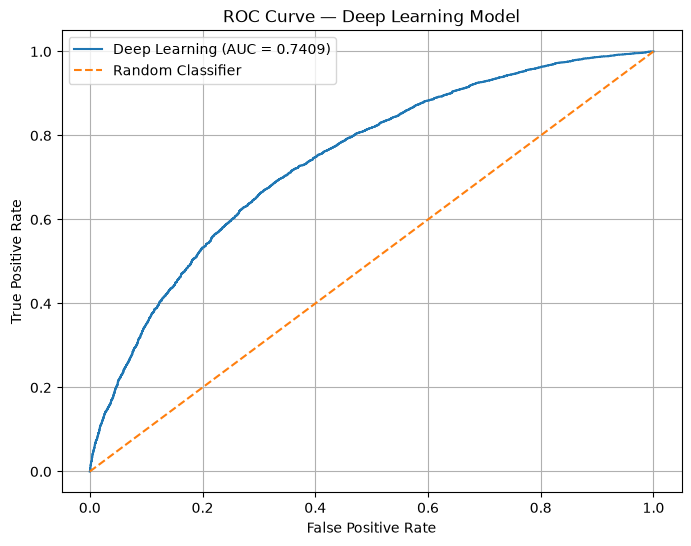

In [97]:
# ============================================================
# ROC CURVE — DEEP LEARNING MODEL
# ============================================================

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_dl, tpr_dl, _ = roc_curve(
    y_test_dl,
    y_dl_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_dl,
    tpr_dl,
    label=f"Deep Learning (AUC = {dl_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Deep Learning Model")
plt.legend()
plt.grid(True)

plt.show()

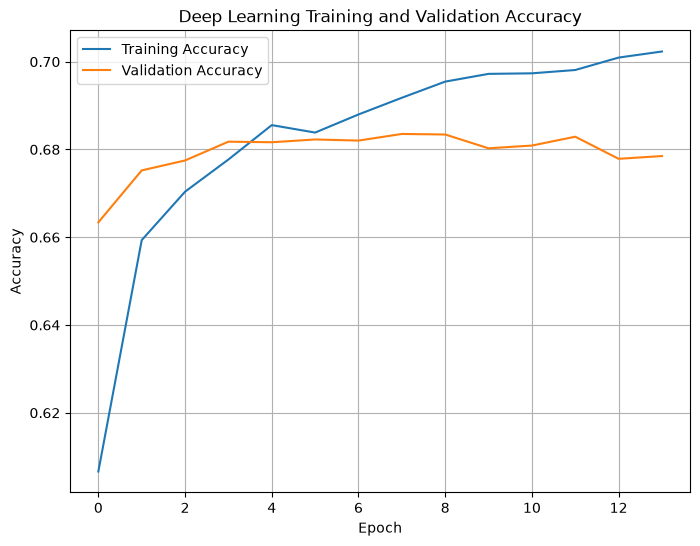

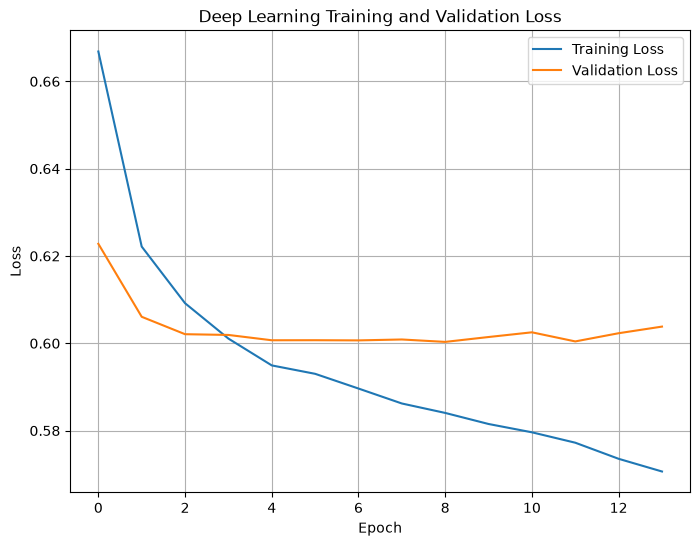

In [98]:
# ============================================================
# TRAINING HISTORY
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep Learning Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(8, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Deep Learning Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [101]:
# ============================================================
# FIX: SAVE KERAS ARCHITECTURE USING UTF-8
# ============================================================

summary_lines = []

deep_learning_model.summary(
    print_fn=summary_lines.append
)

with open(
    "results/deep_learning_model_architecture.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(
        "\n".join(summary_lines)
    )

print("Model architecture saved successfully.")

Model architecture saved successfully.


In [103]:
# ============================================================
# FINAL PROJECT SUMMARY — REPORT DATA
# ============================================================

import os
import json
import pandas as pd
import numpy as np

os.makedirs("results", exist_ok=True)

# ------------------------------------------------------------
# DATASET INFORMATION
# ------------------------------------------------------------

dataset_summary = {
    "original_rows": 307511,
    "original_columns": 122,
    "total_missing_values": 9152465,
    "columns_with_50_percent_or_more_missing": 41,
    "duplicate_rows": 0,
    "natural_test_samples": 61503,
    "natural_test_class_0": 56538,
    "natural_test_class_1": 4965,
    "natural_test_default_rate": 4965 / 61503
}


# ------------------------------------------------------------
# DEEP LEARNING RESULTS
# ------------------------------------------------------------

deep_learning_summary = {
    "model": "Deep Learning Neural Network",
    "accuracy": float(dl_accuracy),
    "precision": float(dl_precision),
    "sensitivity": float(dl_recall),
    "recall": float(dl_recall),
    "f1_score": float(dl_f1),
    "roc_auc": float(dl_roc_auc),
    "specificity": float(dl_specificity),
    "true_negatives": int(tn_dl),
    "false_positives": int(fp_dl),
    "false_negatives": int(fn_dl),
    "true_positives": int(tp_dl)
}


# ------------------------------------------------------------
# LOGISTIC REGRESSION REFERENCE RESULTS
# ------------------------------------------------------------

logistic_summary = {
    "model": "Logistic Regression",
    "accuracy": 0.6847,
    "precision": 0.1587,
    "recall": 0.6753,
    "f1_score": 0.2570,
    "roc_auc": 0.7450,
    "pr_auc": 0.2251,
    "true_negatives": 38758,
    "false_positives": 17780,
    "false_negatives": 1612,
    "true_positives": 3353
}


# ------------------------------------------------------------
# SAVE COMPLETE REPORT DATA
# ------------------------------------------------------------

report_data = {
    "dataset": dataset_summary,
    "deep_learning": deep_learning_summary,
    "logistic_regression_reference": logistic_summary
}

with open(
    "results/final_project_report_data.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        report_data,
        f,
        indent=4
    )


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("FINAL PROJECT REPORT DATA")
print("=" * 75)

print("\nDATASET")
print("-" * 75)

for key, value in dataset_summary.items():
    print(f"{key}: {value}")

print("\nDEEP LEARNING MODEL")
print("-" * 75)

for key, value in deep_learning_summary.items():
    print(f"{key}: {value}")

print("\nLOGISTIC REGRESSION REFERENCE")
print("-" * 75)

for key, value in logistic_summary.items():
    print(f"{key}: {value}")

print("\n" + "=" * 75)
print("Report data saved to:")
print("results/final_project_report_data.json")
print("=" * 75)

FINAL PROJECT REPORT DATA

DATASET
---------------------------------------------------------------------------
original_rows: 307511
original_columns: 122
total_missing_values: 9152465
columns_with_50_percent_or_more_missing: 41
duplicate_rows: 0
natural_test_samples: 61503
natural_test_class_0: 56538
natural_test_class_1: 4965
natural_test_default_rate: 0.08072776937710356

DEEP LEARNING MODEL
---------------------------------------------------------------------------
model: Deep Learning Neural Network
accuracy: 0.6797583081570997
precision: 0.6776826597650806
sensitivity: 0.6855991943605236
recall: 0.6855991943605236
f1_score: 0.6816179415298358
roc_auc: 0.7409138693918861
specificity: 0.6739174219536758
true_negatives: 3346
false_positives: 1619
false_negatives: 1561
true_positives: 3404

LOGISTIC REGRESSION REFERENCE
---------------------------------------------------------------------------
model: Logistic Regression
accuracy: 0.6847
precision: 0.1587
recall: 0.6753
f1_score: 0.2